# Endterm. Project 5: Loan Approval (`Credit Default`)

**Team:** Denis Shin, Abylay Latiyev, Nikita Vassilenko

Data: `Project_eng.zip` (`train_data.csv`, 6,750 rows; `test_data.csv`, 750 rows). No test rows are deleted.

1. [Part 1](#part-1): data quality audit and exploratory data analysis (Denis Shin)
2. [Part 2](#part-2): preprocessing, train/validation split, baseline model (Abylay Latiyev)
3. [Part 3](#part-3): Random Forest and gradient boosting, threshold tuning, comparison by Precision, Recall and F1, error analysis, final test evaluation (Nikita Vassilenko)

Run from the repository root with **Restart Kernel and Run All**. The notebook reads `Project_eng.zip` and imports `credit_pipeline.py` and `participant3.py`. Dependencies are pinned in `requirements.lock.txt` (Python 3.12+).

<a id="part-1"></a>

# Part 1. Data audit and EDA — Denis Shin

This part looks at the raw data and passes its findings to parts 2 and 3. Nothing is cleaned, imputed, encoded, split or trained here; all source values and all 750 test rows stay as they are. The test target is excluded from the analysis.

**Contents:** 1. Load and describe · 2. Quality audit · 3. Missingness and categories · 4. Distributions and IQR candidates · 5. Specific anomalies · 6. Training-target relationships · 7. Recommendations and integrity checks.

**Evaluation boundary:** test predictors are inspected only for the descriptive audit, so test is not an untouched holdout in the strictest sense. Processing choices must come from training data, and every fitted parameter must be learned on the training part after the split. Relationships with the target below are exploratory associations; none of them is validated.

In [1]:
from pathlib import Path
from zipfile import ZipFile
import hashlib
import platform
import textwrap
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 110, 'font.size': 10,
    'axes.titlesize': 11, 'axes.labelsize': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.18,
})
COLORS = {'train': '#2563a6', 'test': '#d77b23', 0: '#2563a6', 1: '#c24646'}
TARGET = 'Credit Default'
archive_path = Path.cwd() / 'Project_eng.zip'
if not archive_path.is_file():
    raise FileNotFoundError('Place Project_eng.zip beside this notebook and run from that directory.')
archive_sha256_before = hashlib.sha256(archive_path.read_bytes()).hexdigest()
def report(*items):
    display(Markdown(' '.join(str(item) for item in items)))

report('Runtime:', platform.python_version(), '| pandas', pd.__version__,
      '| numpy', np.__version__, '| matplotlib', matplotlib.__version__)
report('Archive SHA256 before:', archive_sha256_before)

def show_table(frame, caption):
    display(Markdown(f'**{caption}**'))
    display(frame)

def note(text):
    display(Markdown('**Interpretation.** ' + text))

def wrap(label, width=23):
    return textwrap.fill(str(label), width=width)

Runtime: 3.12.16 | pandas 3.1.1 | numpy 2.5.4 | matplotlib 3.11.2

Archive SHA256 before: 52b39c9c3a85516f3979fb233080000d4baac655366a87cfa8cab8f82bd0f206

### 1. Load and describe the data
The project brief describes a loan-approval task with target `Credit Default` and forbids deleting test rows. It does not say what codes 0 and 1 mean in business terms or which monetary units are used, so we report **class 1** literally; the team still has to confirm its meaning. Feature descriptions below are read from the column names; there is no external data dictionary, and no currency or unit is assumed.

In [2]:
with ZipFile(archive_path) as archive:
    train_raw = pd.read_csv(archive.open('project-5/train_data.csv'))
    test_raw = pd.read_csv(archive.open('project-5/test_data.csv'))

train_snapshot = train_raw.copy(deep=True)
test_snapshot = test_raw.copy(deep=True)
assert train_raw.shape == (6750, 17)
assert test_raw.shape == (750, 17)
assert TARGET in train_raw and TARGET in test_raw
X_train = train_raw.drop(columns=[TARGET]).copy()
X_test = test_raw.drop(columns=[TARGET]).copy()
y_train = train_raw[TARGET].copy()
assert TARGET not in X_train and TARGET not in X_test
assert y_train.notna().all() and set(y_train.unique()) == {0, 1}
numeric_cols = X_train.select_dtypes(include='number').columns.tolist()
categorical_cols = [c for c in X_train.columns if c not in numeric_cols]
datasets = {'train': X_train, 'test': X_test}

show_table(pd.DataFrame({
    'source rows': [len(train_raw), len(test_raw)],
    'source columns': [train_raw.shape[1], test_raw.shape[1]],
    'EDA predictor columns': [X_train.shape[1], X_test.shape[1]],
    'target used in EDA': ['yes, train only', 'no'],
}, index=['train', 'test']), 'Dataset dimensions and target boundary')
show_table(X_train.head(), 'Training predictors: first five rows (target excluded)')

**Dataset dimensions and target boundary**

,source rows,source columns,EDA predictor columns,target used in EDA
train,6750,17,16,"yes, train only"
test,750,17,16,no


**Training predictors: first five rows (target excluded)**

,Home Ownership,Annual Income,Years in current job,Tax Liens,Number of Open Accounts,Years of Credit History,Maximum Open Credit,Number of Credit Problems,Months since last delinquent,Bankruptcies,Purpose,Term,Current Loan Amount,Current Credit Balance,Monthly Debt,Credit Score
0,Home Mortgage,NaN,10+ years,0.000,10.000,21.800,"267,762.000",0.000,NaN,0.000,debt consolidation,Short Term,"193,358.000","140,372.000","19,404.000",NaN
1,Rent,"767,904.000",1 year,0.000,9.000,15.400,"275,528.000",0.000,73.000,0.000,debt consolidation,Short Term,"222,288.000","168,226.000","18,302.000",718.000
2,Own Home,NaN,9 years,0.000,14.000,27.100,"1,635,590.000",1.000,NaN,0.000,debt consolidation,Short Term,"433,268.000","1,017,032.000","15,295.000",NaN
3,Home Mortgage,"1,267,395.000",3 years,0.000,11.000,11.800,"137,676.000",1.000,61.000,0.000,home improvements,Short Term,"99,999,999.000","34,124.000","25,559.000",719.000
4,Rent,"1,813,493.000",7 years,0.000,19.000,14.000,"501,556.000",0.000,6.000,0.000,debt consolidation,Short Term,"265,232.000","114,779.000","23,877.000",713.000


In [3]:
descriptions = {
    'Home Ownership': 'Reported housing or mortgage category.',
    'Annual Income': 'Reported yearly income; currency not documented.',
    'Years in current job': 'Employment tenure stored as category labels.',
    'Tax Liens': 'Reported count of tax liens.',
    'Number of Open Accounts': 'Reported count of open credit accounts.',
    'Years of Credit History': 'Length of credit history in years.',
    'Maximum Open Credit': 'Reported maximum open credit; monetary units undocumented.',
    'Number of Credit Problems': 'Reported count of credit problems.',
    'Months since last delinquent': 'Months since the last delinquency; missingness meaning undocumented.',
    'Bankruptcies': 'Reported bankruptcy count.',
    'Purpose': 'Stated loan purpose.',
    'Term': 'Categorical loan term.',
    'Current Loan Amount': 'Reported current loan amount; monetary units undocumented.',
    'Current Credit Balance': 'Reported current credit balance.',
    'Monthly Debt': 'Reported monthly debt amount.',
    'Credit Score': 'Reported credit score; scale requires confirmation.',
    TARGET: 'Binary training target; business meaning of 0/1 requires confirmation.',
}
dictionary = pd.DataFrame({
    'column': train_raw.columns,
    'role': ['target' if c == TARGET else 'predictor' for c in train_raw],
    'storage dtype': [str(train_raw[c].dtype) for c in train_raw],
    'description inferred from name': [descriptions[c] for c in train_raw],
})
show_table(dictionary.set_index('column'), 'Column roles and meanings')
note(f'There are {len(numeric_cols)} numeric and {len(categorical_cols)} categorical predictors. '
     'Numeric storage does not imply a continuous measurement: several float columns represent counts. '
     'The two source files each contain 17 columns; the EDA feature frames each contain 16.')

**Column roles and meanings**

,role,storage dtype,description inferred from name
column,,,
Home Ownership,predictor,str,Reported housing or mortgage category.
Annual Income,predictor,float64,Reported yearly income; currency not documented.
Years in current job,predictor,str,Employment tenure stored as category labels.
Tax Liens,predictor,float64,Reported count of tax liens.
Number of Open Accounts,predictor,float64,Reported count of open credit accounts.
Years of Credit History,predictor,float64,Length of credit history in years.
Maximum Open Credit,predictor,float64,Reported maximum open credit; monetary units u...
Number of Credit Problems,predictor,float64,Reported count of credit problems.
Months since last delinquent,predictor,float64,Months since the last delinquency; missingness...


**Interpretation.** There are 12 numeric and 4 categorical predictors. Numeric storage does not imply a continuous measurement: several float columns represent counts. The two source files each contain 17 columns; the EDA feature frames each contain 16.

### 2. Audit data quality and compare schemas
Missing percentages use all rows in the relevant dataset as the denominator. Infinity and negative
counts refer to observed numeric values. A duplicate means equality across all compared columns;
it does not identify duplicate people because no person identifier is supplied.

In [4]:
schema = pd.DataFrame(index=X_train.columns.union(X_test.columns, sort=False))
schema['in train'] = schema.index.isin(X_train.columns)
schema['in test'] = schema.index.isin(X_test.columns)
schema['train dtype'] = X_train.dtypes.astype(str).reindex(schema.index)
schema['test dtype'] = X_test.dtypes.astype(str).reindex(schema.index)
schema['same dtype'] = schema['train dtype'].eq(schema['test dtype'])
show_table(schema, 'Predictor schema comparison')
assert X_train.columns.equals(X_test.columns)
assert schema['same dtype'].all()

quality_tables = []
for name, frame in datasets.items():
    quality = pd.DataFrame(index=frame.columns)
    quality['dataset'] = name
    quality['dtype'] = frame.dtypes.astype(str)
    quality['observed unique'] = frame.nunique(dropna=True)
    quality['missing n'] = frame.isna().sum()
    quality['missing %'] = frame.isna().mean().mul(100)
    quality['infinite n'] = [int(np.isinf(frame[c].dropna()).sum()) if c in numeric_cols else 0 for c in frame]
    quality['negative n'] = [int(frame[c].lt(0).sum()) if c in numeric_cols else 0 for c in frame]
    quality_tables.append(quality.rename_axis('feature').reset_index())
quality_audit = pd.concat(quality_tables, ignore_index=True)
show_table(quality_audit.set_index(['dataset', 'feature']), 'Complete predictor quality audit')
duplicate_audit = pd.DataFrame({
    'dataset': ['train', 'test'],
    'duplicate predictor rows': [int(X_train.duplicated().sum()), int(X_test.duplicated().sum())],
    'duplicate source rows (train only)': [int(train_raw.duplicated().sum()), pd.NA],
})
show_table(duplicate_audit.set_index('dataset'), 'Duplicate counts (extra copies beyond first)')
cross_overlap = X_test.merge(X_train.drop_duplicates(), how='inner', on=list(X_train.columns)).shape[0]
report('Exact shared predictor rows between train and test:', cross_overlap)
report('Training target missing values:', int(y_train.isna().sum()))
note(f'Predictor names, order and dtypes match. There are '
     f'{quality_audit["infinite n"].sum():,} infinite and {quality_audit["negative n"].sum():,} negative '
     'numeric entries across both predictor frames. No duplicate predictor rows occur within either '
     f'file; exact cross-file predictor overlap is {cross_overlap}. These checks do not establish '
     'that the data are otherwise valid: missing values and suspicious magnitudes still need investigation.')

**Predictor schema comparison**

,in train,in test,train dtype,test dtype,same dtype
Home Ownership,True,True,str,str,True
Annual Income,True,True,float64,float64,True
Years in current job,True,True,str,str,True
Tax Liens,True,True,float64,float64,True
Number of Open Accounts,True,True,float64,float64,True
Years of Credit History,True,True,float64,float64,True
Maximum Open Credit,True,True,float64,float64,True
Number of Credit Problems,True,True,float64,float64,True
Months since last delinquent,True,True,float64,float64,True
Bankruptcies,True,True,float64,float64,True


**Complete predictor quality audit**

dtype  observed unique  missing n  \
dataset feature                                                             
train   Home Ownership                    str                4          0   
        Annual Income                 float64             4972       1400   
        Years in current job              str               11        332   
        Tax Liens                     float64                8          0   
        Number of Open Accounts       float64               38          0   
        Years of Credit History       float64              403          0   
        Maximum Open Credit           float64             6307          0   
        Number of Credit Problems     float64                8          0   
        Months since last delinquent  float64               89       3675   
        Bankruptcies                  float64                5         12   
        Purpose                           str               15          0   
        Term                              str                2          0   
        Current Loan Amount           float64             4927          0   
        Current Credit Balance        float64             6006          0   
        Monthly Debt                  float64             6108          0   
        Credit Score                  float64              260       1400   
test    Home Ownership                    str                4          0   
        Annual Income                 float64              590        157   
        Years in current job              str               11         39   
        Tax Liens                     float64                5          0   
        Number of Open Accounts       float64               30          0   
        Years of Credit History       float64              237          0   
        Maximum Open Credit           float64              739          0   
        Number of Credit Problems     float64                6          0   
        Months since last delinquent  float64               81        406   
        Bankruptcies                  float64                4          2   
        Purpose                           str               13          0   
        Term                              str                2          0   
        Current Loan Amount           float64              647          0   
        Current Credit Balance        float64              734          0   
        Monthly Debt                  float64              742          0   
        Credit Score                  float64              134        157   

                                      missing %  infinite n  negative n  
dataset feature                                                          
train   Home Ownership                    0.000           0           0  
        Annual Income                    20.741           0           0  
        Years in current job              4.919           0           0  
        Tax Liens                         0.000           0           0  
        Number of Open Accounts           0.000           0           0  
        Years of Credit History           0.000           0           0  
        Maximum Open Credit               0.000           0           0  
        Number of Credit Problems         0.000           0           0  
        Months since last delinquent     54.444           0           0  
        Bankruptcies                      0.178           0           0  
        Purpose                           0.000           0           0  
        Term                              0.000           0           0  
        Current Loan Amount               0.000           0           0  
        Current Credit Balance            0.000           0           0  
        Monthly Debt                      0.000           0           0  
        Credit Score                     20.741           0           0  
test    Home Ownership                    0.000           0           0  
        Annual 

**Duplicate counts (extra copies beyond first)**

,duplicate predictor rows,duplicate source rows (train only)
dataset,,
train,0,0
test,0,<NA>


Exact shared predictor rows between train and test: 0

Training target missing values: 0

**Interpretation.** Predictor names, order and dtypes match. There are 0 infinite and 0 negative numeric entries across both predictor frames. No duplicate predictor rows occur within either file; exact cross-file predictor overlap is 0. These checks do not establish that the data are otherwise valid: missing values and suspicious magnitudes still need investigation.

### 3. Missingness and categorical values
Missingness patterns are compared on predictors only. A **rare category** here is a non-missing level with fewer than 1% of training rows. This threshold only describes the data; part 2 fits its own grouping rule. `<missing>` is a display label and does not change either feature frame.

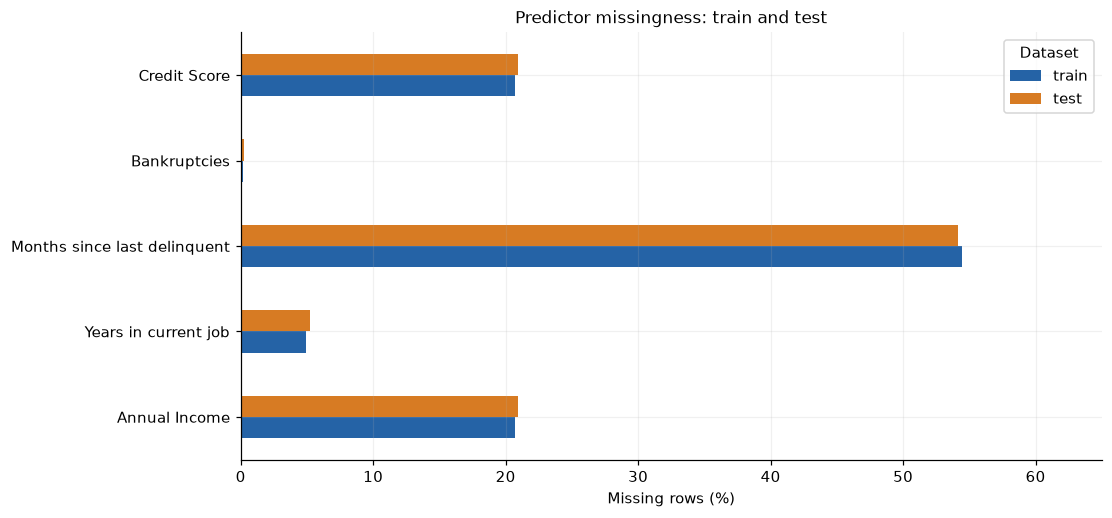

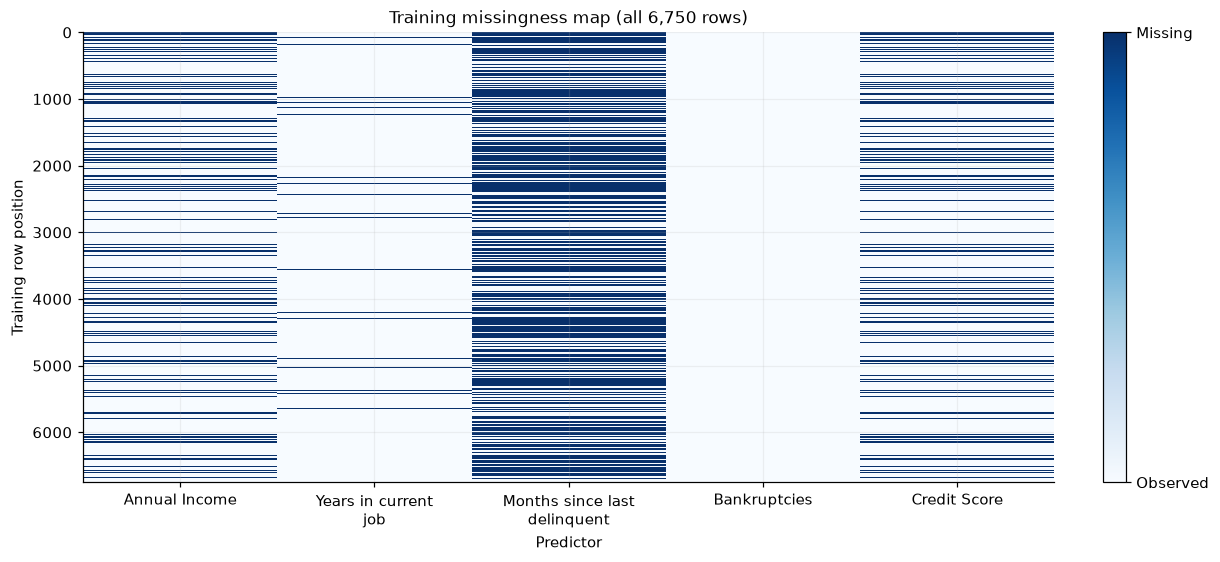

**Annual Income / Credit Score joint missingness**

,both observed,both missing,income missing only,score missing only,identical missing masks
dataset,,,,,
train,5350,1400,0,0,True
test,593,157,0,0,True


**All observed training missingness patterns (True = missing)**

,Annual Income,Years in current job,Months since last delinquent,Bankruptcies,Credit Score,train rows
0,False,False,True,False,False,2751
1,False,False,False,False,False,2323
2,True,False,True,False,True,747
3,True,False,False,False,True,585
4,False,True,True,False,False,144
5,False,True,False,False,False,121
6,True,True,False,False,True,34
7,True,True,True,False,True,33
8,False,False,False,True,False,11
9,True,False,False,True,True,1


**Interpretation.** Months since last delinquent is missing for 54.44% of train and 54.13% of test. Income and score are missing on exactly the same rows in each file (1,400 train; 157 test). Co-missingness suggests a shared collection process, but does not prove the reason. Do not interpret absent delinquency months as “never delinquent” without documentation.

In [5]:
missing_pct = pd.DataFrame({name: frame.isna().mean().mul(100) for name, frame in datasets.items()})
missing_cols = missing_pct.index[missing_pct.max(axis=1).gt(0)].tolist()
fig, ax = plt.subplots(figsize=(10, 4.6), layout='constrained')
missing_pct.loc[missing_cols].plot.barh(ax=ax, color=[COLORS['train'], COLORS['test']])
ax.set(xlabel='Missing rows (%)', ylabel='', title='Predictor missingness: train and test', xlim=(0, 65))
ax.legend(title='Dataset')
plt.show()

fig, ax = plt.subplots(figsize=(11, 5), layout='constrained')
image = ax.imshow(X_train[missing_cols].isna().to_numpy(), aspect='auto', interpolation='nearest',
                  cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(len(missing_cols)), [wrap(c, 18) for c in missing_cols])
ax.set(xlabel='Predictor', ylabel='Training row position', title='Training missingness map (all 6,750 rows)')
cbar = fig.colorbar(image, ax=ax, ticks=[0, 1], fraction=0.03)
cbar.ax.set_yticklabels(['Observed', 'Missing'])
plt.show()

co_missing_rows = []
for name, frame in datasets.items():
    income_missing = frame['Annual Income'].isna()
    score_missing = frame['Credit Score'].isna()
    co_missing_rows.append({
        'dataset': name, 'both observed': int((~income_missing & ~score_missing).sum()),
        'both missing': int((income_missing & score_missing).sum()),
        'income missing only': int((income_missing & ~score_missing).sum()),
        'score missing only': int((~income_missing & score_missing).sum()),
        'identical missing masks': bool(income_missing.equals(score_missing)),
    })
co_missing = pd.DataFrame(co_missing_rows).set_index('dataset')
show_table(co_missing, 'Annual Income / Credit Score joint missingness')
pattern_counts = X_train[missing_cols].isna().value_counts().rename('train rows').reset_index()
show_table(pattern_counts, 'All observed training missingness patterns (True = missing)')
note(f'Months since last delinquent is missing for {X_train["Months since last delinquent"].isna().mean():.2%} '
     'of train and ' + f'{X_test["Months since last delinquent"].isna().mean():.2%} of test. '
     'Income and score are missing on exactly the same rows in each file '
     f'({co_missing.loc["train", "both missing"]:,} train; {co_missing.loc["test", "both missing"]:,} test). '
     'Co-missingness suggests a shared collection process, but does not prove the reason. '
     'Do not interpret absent delinquency months as “never delinquent” without documentation.')

**Home Ownership: complete category inventory, counts and percentages**

,train n,test n,train %,test %,rare in train (<1%)
Home Ownership,,,,,
Home Mortgage,3279,358,48.578,47.733,False
Rent,2882,322,42.696,42.933,False
Own Home,579,68,8.578,9.067,False
Have Mortgage,10,2,0.148,0.267,True


**Years in current job: complete category inventory, counts and percentages**

,train n,test n,train %,test %,rare in train (<1%)
Years in current job,,,,,
10+ years,2098,234,31.081,31.200,False
2 years,639,66,9.467,8.800,False
3 years,566,54,8.385,7.200,False
< 1 year,501,62,7.422,8.267,False
5 years,464,52,6.874,6.933,False
1 year,437,67,6.474,8.933,False
4 years,426,43,6.311,5.733,False
6 years,390,36,5.778,4.800,False
7 years,355,41,5.259,5.467,False


**Purpose: complete category inventory, counts and percentages**

,train n,test n,train %,test %,rare in train (<1%)
Purpose,,,,,
debt consolidation,5326,618,78.904,82.400,False
other,616,49,9.126,6.533,False
home improvements,374,38,5.541,5.067,False
business loan,118,11,1.748,1.467,False
buy a car,86,10,1.274,1.333,False
medical bills,62,9,0.919,1.200,True
major purchase,39,1,0.578,0.133,True
take a trip,33,4,0.489,0.533,True
buy house,33,1,0.489,0.133,True


**Term: complete category inventory, counts and percentages**

,train n,test n,train %,test %,rare in train (<1%)
Term,,,,,
Short Term,5004,552,74.133,73.600,False
Long Term,1746,198,25.867,26.400,False


**Category coverage and rare-level audit**

,train levels,test levels,test-only levels,train-only levels,rare train levels
feature,,,,,
Home Ownership,4,4,(none),(none),1
Years in current job,11,11,(none),(none),0
Purpose,15,13,(none),"educational expenses, renewable energy",10
Term,2,2,(none),(none),0


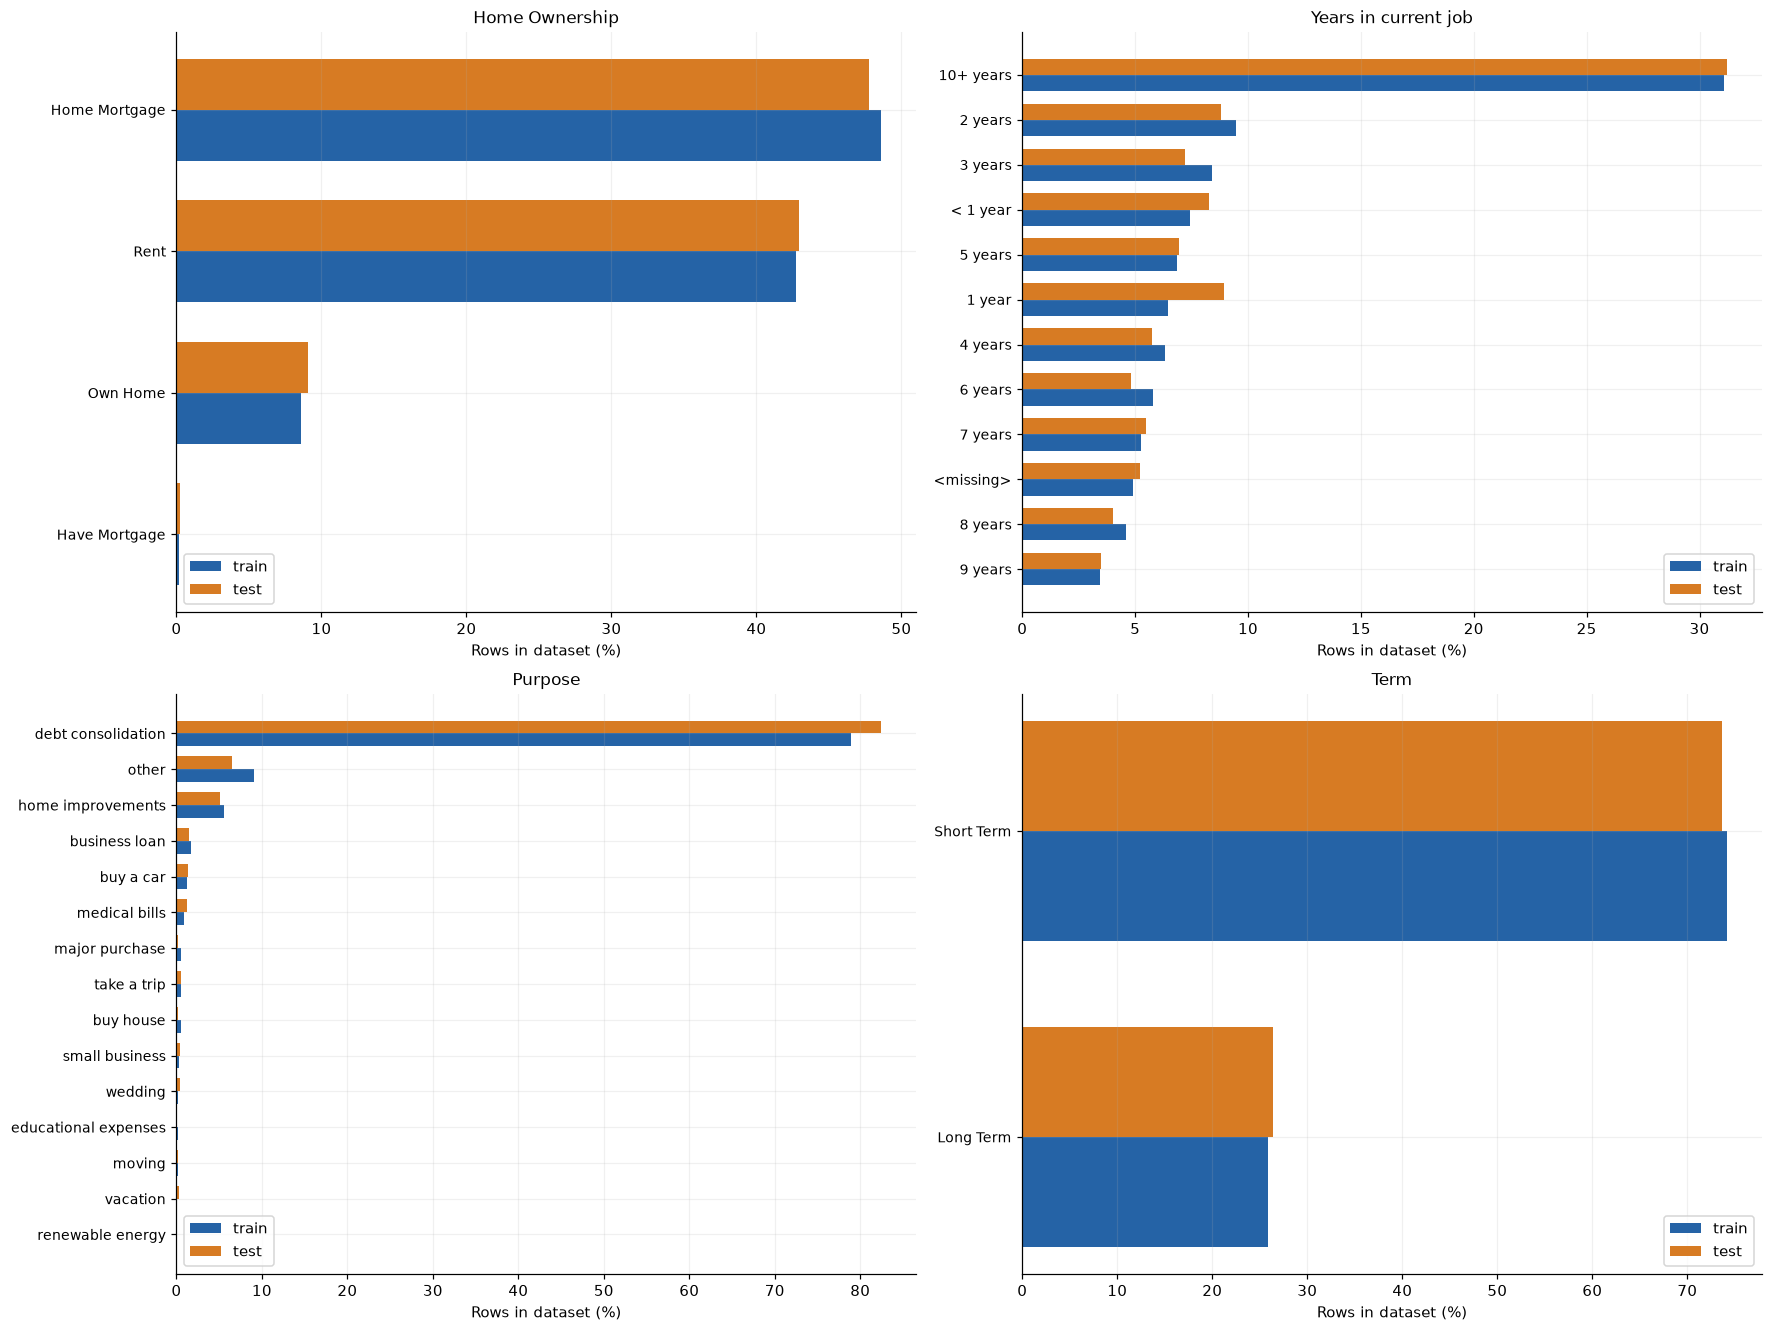

**Interpretation.** Every observed non-missing test category also appears in train. Purpose levels “educational expenses” and “renewable energy” appear only in train. Debt consolidation dominates Purpose; small levels require cautious comparisons. “Have Mortgage” and “Home Mortgage” look semantically similar, but merging them requires confirmation. Employment tenure has an ordered meaning despite string storage; “< 1 year” and “10+ years” are bounded labels, not exact durations. A future encoder still needs an explicit unknown-category strategy.

In [6]:
category_tables = {}
category_checks = []
for col in categorical_cols:
    counts = pd.DataFrame({name: frame[col].fillna('<missing>').value_counts()
                           for name, frame in datasets.items()}).fillna(0).astype(int)
    counts.columns = ['train n', 'test n']
    counts['train %'] = counts['train n'].div(len(X_train)).mul(100)
    counts['test %'] = counts['test n'].div(len(X_test)).mul(100)
    counts['rare in train (<1%)'] = (counts['train n'].gt(0) & counts['train %'].lt(1)
                                      & counts.index.to_series().ne('<missing>'))
    counts = counts.sort_values('train n', ascending=False)
    category_tables[col] = counts
    train_levels = set(X_train[col].dropna().unique())
    test_levels = set(X_test[col].dropna().unique())
    category_checks.append({
        'feature': col, 'train levels': len(train_levels), 'test levels': len(test_levels),
        'test-only levels': ', '.join(sorted(test_levels - train_levels)) or '(none)',
        'train-only levels': ', '.join(sorted(train_levels - test_levels)) or '(none)',
        'rare train levels': int(counts['rare in train (<1%)'].sum()),
    })
    show_table(counts, f'{col}: complete category inventory, counts and percentages')
category_audit = pd.DataFrame(category_checks).set_index('feature')
show_table(category_audit, 'Category coverage and rare-level audit')

fig, axes = plt.subplots(2, 2, figsize=(16, 12), layout='constrained')
for ax, col in zip(axes.flat, categorical_cols):
    counts = category_tables[col].iloc[::-1]
    positions = np.arange(len(counts))
    ax.barh(positions - 0.18, counts['train %'], height=0.36, color=COLORS['train'], label='train')
    ax.barh(positions + 0.18, counts['test %'], height=0.36, color=COLORS['test'], label='test')
    ax.set_yticks(positions, [wrap(v, 21) for v in counts.index], fontsize=9)
    ax.set(title=col, xlabel='Rows in dataset (%)')
    ax.legend()
plt.show()
note('Every observed non-missing test category also appears in train. Purpose levels '
     '“educational expenses” and “renewable energy” appear only in train. '
     'Debt consolidation dominates Purpose; small levels require cautious comparisons. '
     '“Have Mortgage” and “Home Mortgage” look semantically similar, but merging them requires '
     'confirmation. Employment tenure has an ordered meaning despite string storage; '
     '“< 1 year” and “10+ years” are bounded labels, not exact durations. '
     'A future encoder still needs an explicit unknown-category strategy.')

### 4. Numeric distributions and outlier candidates
Statistics and raw plots include every observed value. Missing values are skipped per feature; no source rows are deleted. The IQR rule is calculated on **train only**: `lower = Q1 - 1.5 × IQR`, `upper = Q3 + 1.5 × IQR`, and values strictly outside are candidates. The same train fences are shown against test predictors for comparison. These diagnostics are exploratory; they do not set parameters for the final pipeline.

**Train: numeric descriptive statistics (raw values)**

,count,mean,std,min,1%,25%,50%,75%,99%,max,missing n,skewness
Annual Income,"5,350.000","1,368,477.944","844,312.850","164,597.000","330,494.170","845,989.250","1,170,913.000","1,643,780.250","4,576,060.320","9,338,880.000",1400,2.956
Tax Liens,"6,750.000",0.029,0.269,0.000,0.000,0.000,0.000,0.000,1.000,7.000,0,13.522
Number of Open Accounts,"6,750.000",11.129,4.903,2.000,3.000,8.000,10.000,14.000,26.510,43.000,0,1.107
Years of Credit History,"6,750.000",18.325,7.076,4.000,6.500,13.500,17.000,21.800,40.500,57.700,0,1.060
Maximum Open Credit,"6,750.000","904,896.787","16,226,437.591",0.000,"17,302.780","279,537.500","477,114.000","790,625.000","3,538,121.400","1,304,726,170.000",0,77.536
Number of Credit Problems,"6,750.000",0.170,0.497,0.000,0.000,0.000,0.000,0.000,2.000,7.000,0,4.605
Months since last delinquent,"3,075.000",34.738,21.732,0.000,1.000,16.000,32.000,50.000,80.000,118.000,3675,0.434
Bankruptcies,"6,738.000",0.118,0.348,0.000,0.000,0.000,0.000,0.000,1.000,4.000,12,3.177
Current Loan Amount,"6,750.000","11,873,069.229","31,926,402.077","11,242.000","43,196.780","179,619.000","309,936.000","519,475.000","99,999,999.000","99,999,999.000",0,2.399
Current Credit Balance,"6,750.000","288,831.897","321,473.417",0.000,"1,453.310","112,674.750","208,449.000","359,883.750","1,485,748.890","6,506,797.000",0,5.388


**Test: numeric descriptive statistics (raw values)**

,count,mean,std,min,1%,25%,50%,75%,99%,max,missing n,skewness
Annual Income,593.000,"1,347,569.970","855,032.369","233,453.000","318,284.200","827,051.000","1,157,974.000","1,595,354.000","3,926,422.200","10,149,344.000",157,3.692
Tax Liens,750.000,0.037,0.294,0.000,0.000,0.000,0.000,0.000,1.510,4.000,0,9.262
Number of Open Accounts,750.000,11.148,4.968,2.000,3.000,8.000,10.000,14.000,26.510,42.000,0,1.208
Years of Credit History,750.000,18.246,6.730,5.300,7.000,13.900,17.000,21.875,39.000,44.000,0,0.900
Maximum Open Credit,750.000,"1,307,466.189","14,101,368.783",0.000,"3,212.440","271,287.500","488,510.000","832,496.500","3,797,319.460","380,052,288.000",0,26.053
Number of Credit Problems,750.000,0.172,0.513,0.000,0.000,0.000,0.000,0.000,2.000,5.000,0,4.230
Months since last delinquent,344.000,34.288,21.323,0.000,1.000,17.000,30.000,51.000,80.000,83.000,406,0.401
Bankruptcies,748.000,0.106,0.337,0.000,0.000,0.000,0.000,0.000,1.000,4.000,2,4.127
Current Loan Amount,750.000,"11,874,151.388","31,944,915.016","26,334.000","43,073.360","197,829.500","303,545.000","525,530.500","99,999,999.000","99,999,999.000",0,2.403
Current Credit Balance,750.000,"298,845.275","283,435.502",0.000,"2,439.790","122,065.500","219,383.500","363,223.000","1,430,562.060","2,240,594.000",0,2.660


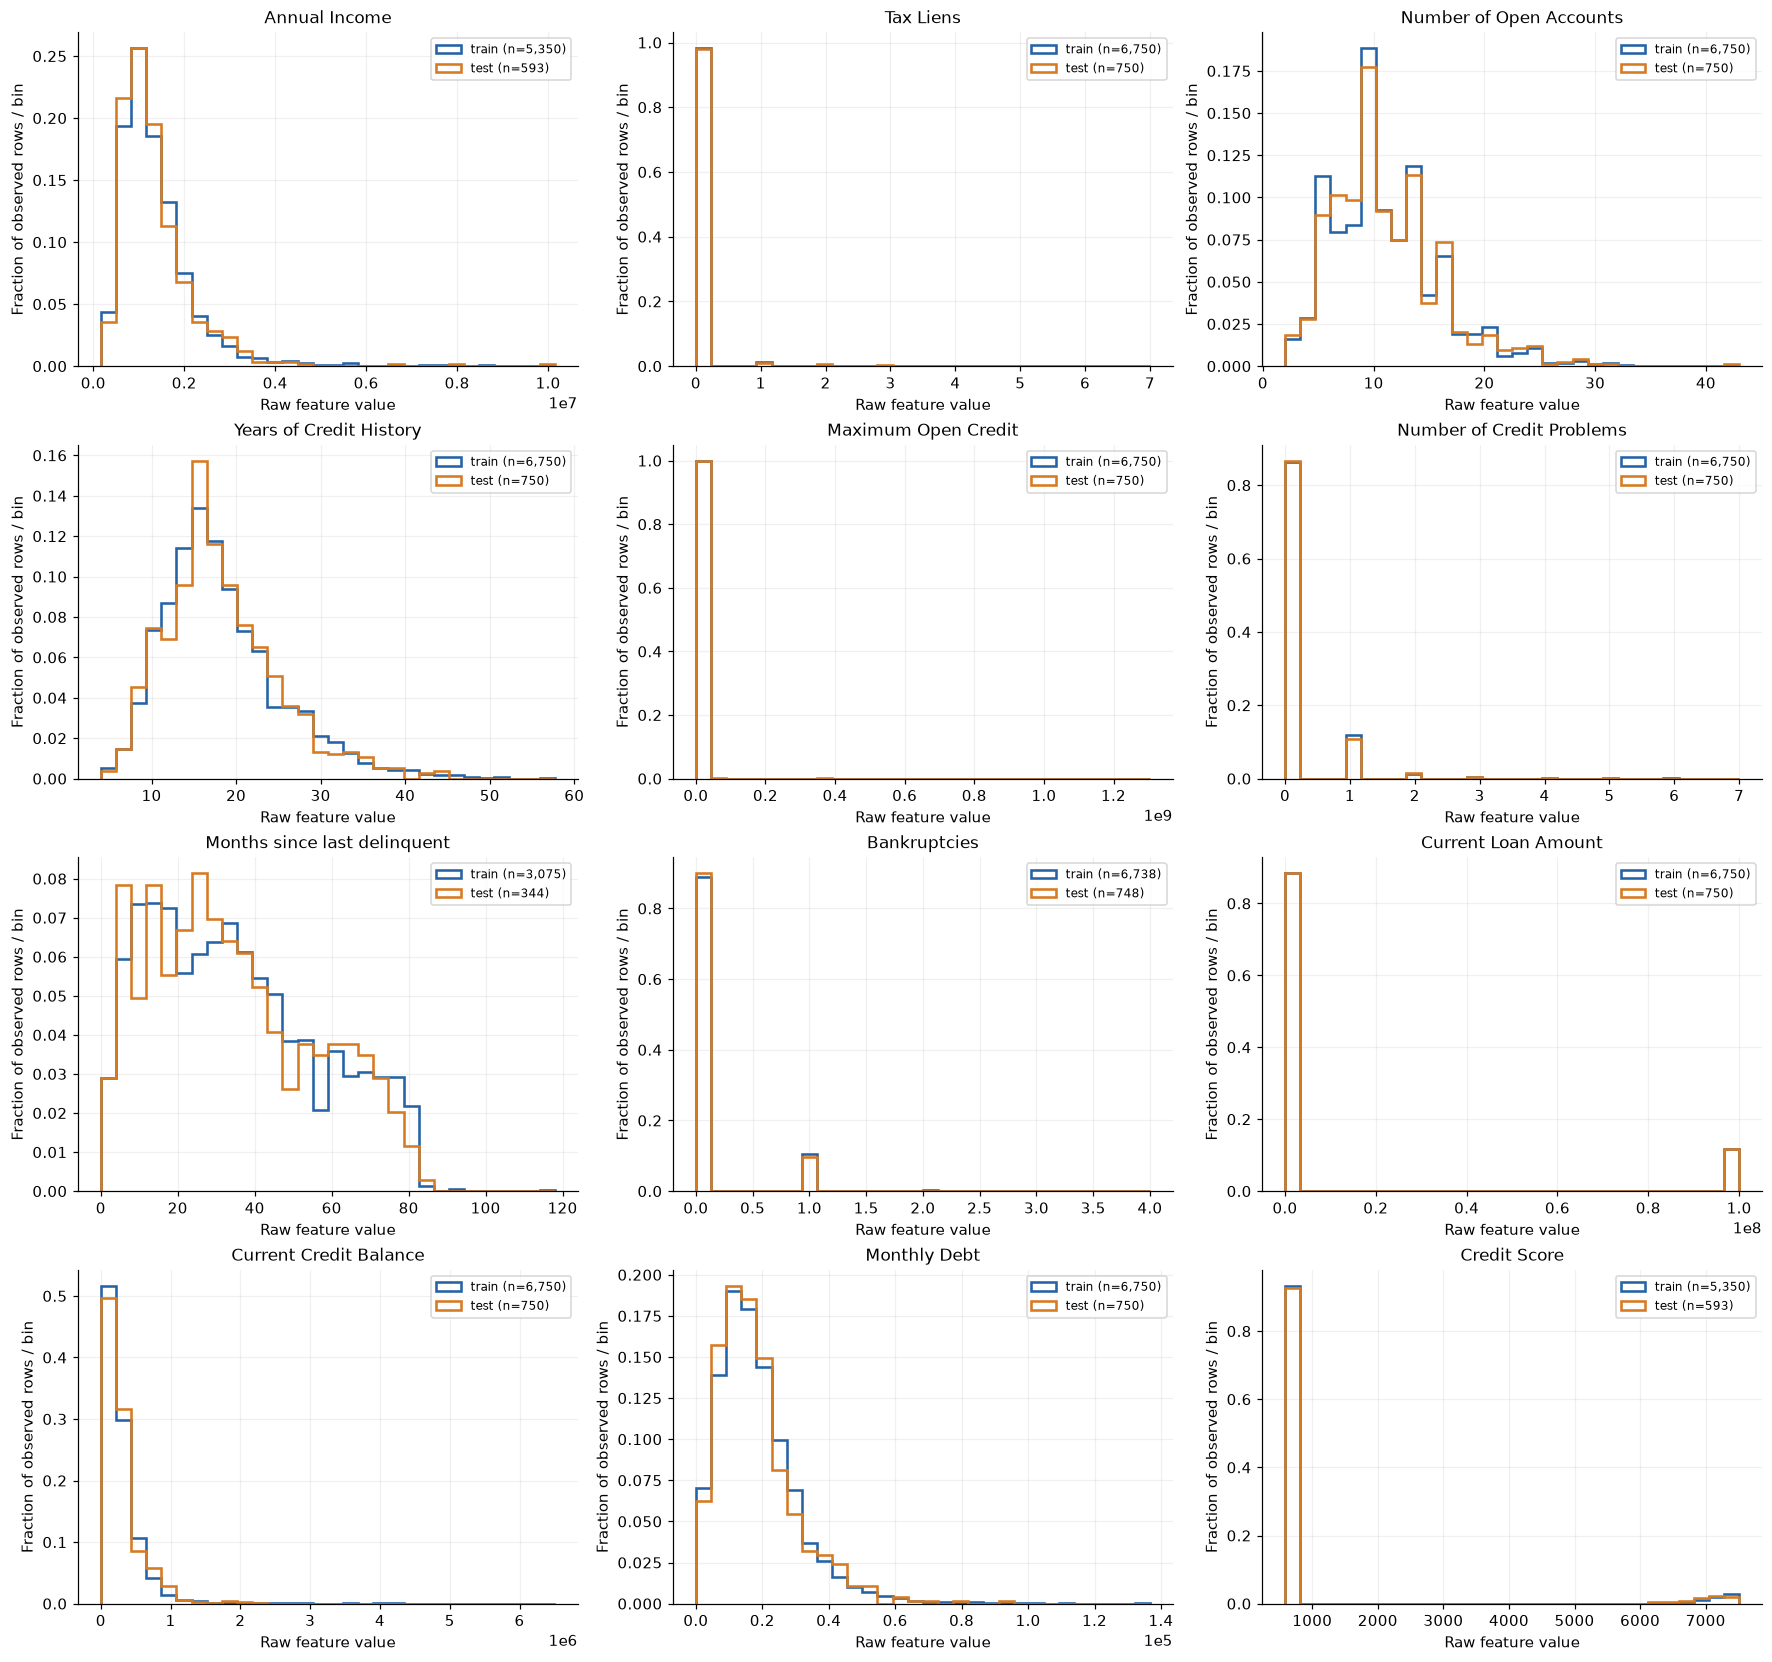

In [7]:
for name, frame in datasets.items():
    summary = frame[numeric_cols].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
    summary['missing n'] = frame[numeric_cols].isna().sum()
    summary['skewness'] = frame[numeric_cols].skew()
    show_table(summary, f'{name.title()}: numeric descriptive statistics (raw values)')

fig, axes = plt.subplots(4, 3, figsize=(16, 15), layout='constrained')
for ax, col in zip(axes.flat, numeric_cols):
    observed_train = X_train[col].dropna()
    observed_test = X_test[col].dropna()
    edges = np.histogram_bin_edges(pd.concat([observed_train, observed_test]), bins=30)
    for name, observed in [('train', observed_train), ('test', observed_test)]:
        ax.hist(observed, bins=edges, weights=np.full(len(observed), 1 / len(observed)),
                histtype='step', linewidth=1.7, label=f'{name} (n={len(observed):,})', color=COLORS[name])
    ax.set(title=wrap(col, 30), xlabel='Raw feature value', ylabel='Fraction of observed rows / bin')
    ax.ticklabel_format(axis='x', style='sci', scilimits=(-3, 5))
    ax.legend(fontsize=8)
plt.show()

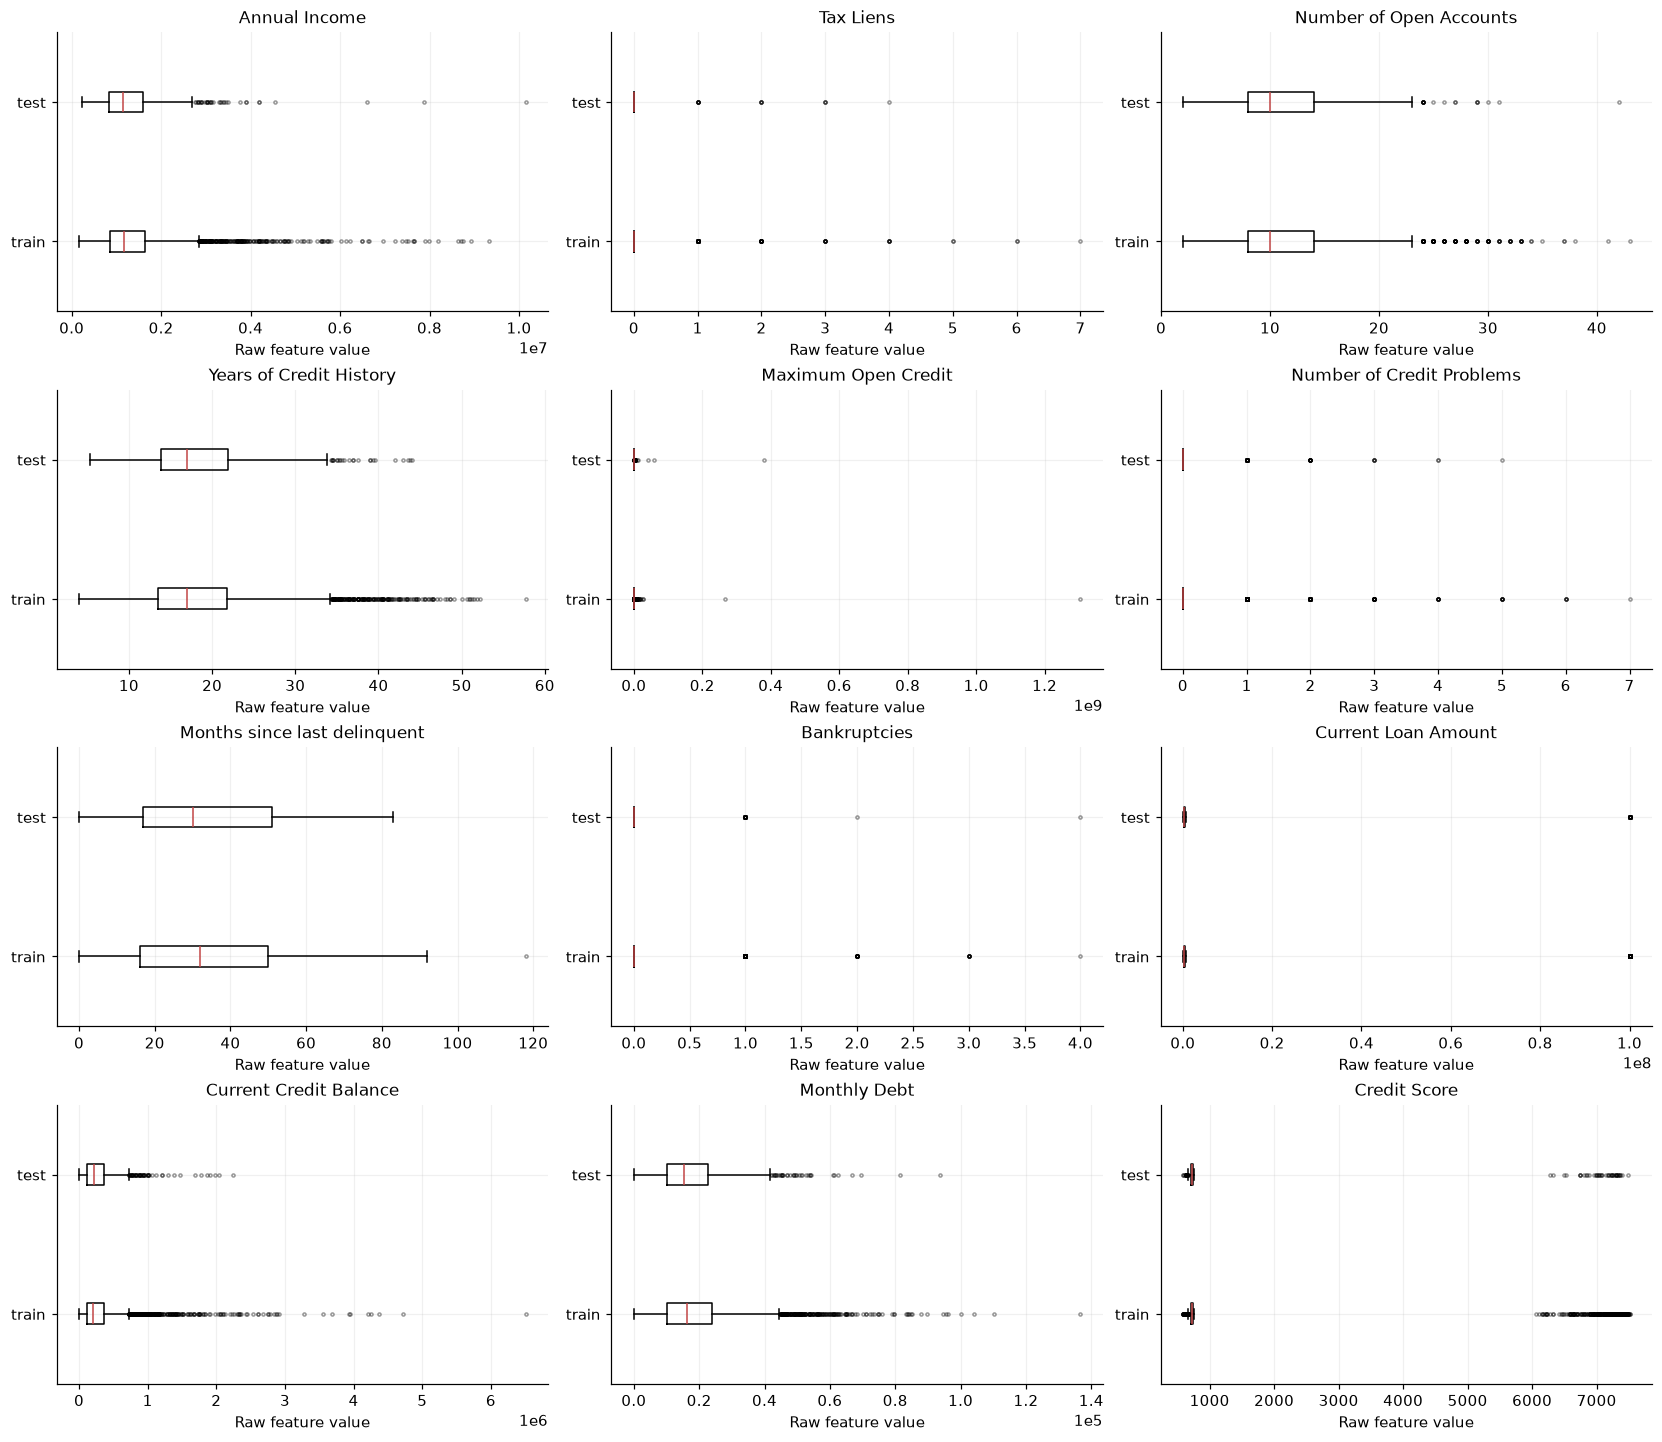

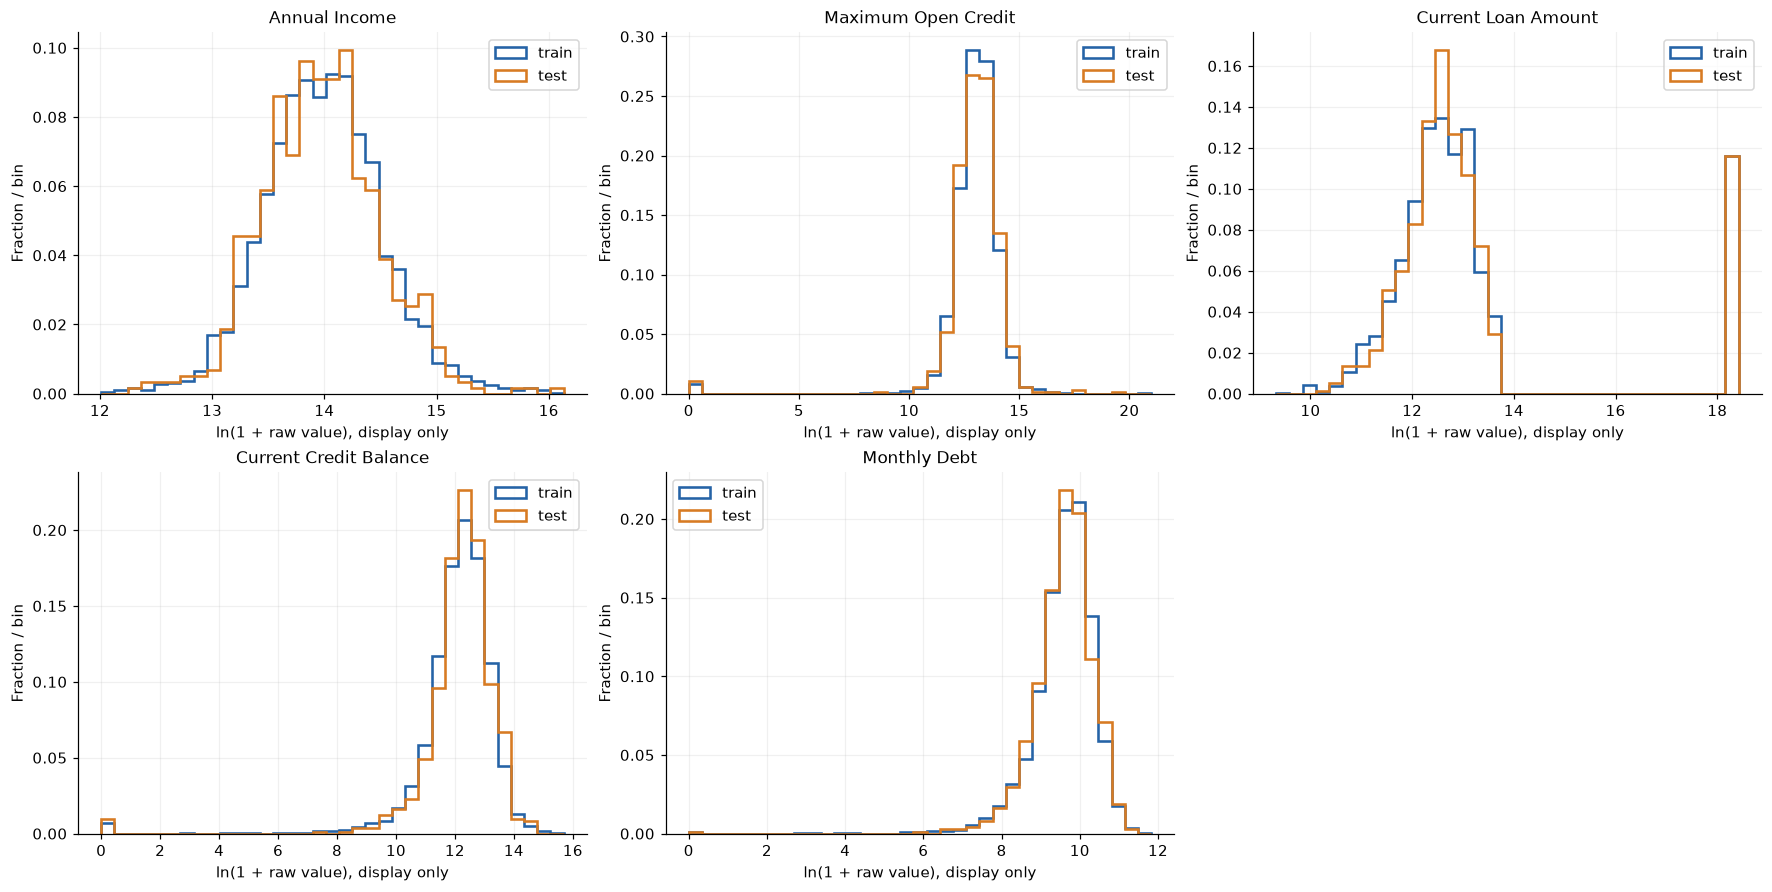

In [8]:
fig, axes = plt.subplots(4, 3, figsize=(15, 13), layout='constrained')
for ax, col in zip(axes.flat, numeric_cols):
    ax.boxplot([X_train[col].dropna().to_numpy(), X_test[col].dropna().to_numpy()],
               tick_labels=['train', 'test'], orientation='horizontal',
               flierprops={'markersize': 2, 'alpha': 0.4}, medianprops={'color': '#c24646'})
    ax.set(title=wrap(col, 30), xlabel='Raw feature value')
    ax.ticklabel_format(axis='x', style='sci', scilimits=(-3, 5))
plt.show()

money_cols = ['Annual Income', 'Maximum Open Credit', 'Current Loan Amount',
              'Current Credit Balance', 'Monthly Debt']
fig, axes = plt.subplots(2, 3, figsize=(16, 8), layout='constrained')
for ax, col in zip(axes.flat, money_cols):
    # Display transformation only: no source column is replaced.
    values = {name: np.log1p(frame[col].dropna()) for name, frame in datasets.items()}
    edges = np.histogram_bin_edges(pd.concat(list(values.values())), bins=35)
    for name, observed in values.items():
        ax.hist(observed, bins=edges, weights=np.full(len(observed), 1 / len(observed)),
                histtype='step', linewidth=1.7, color=COLORS[name], label=name)
    ax.set(title=wrap(col, 30), xlabel='ln(1 + raw value), display only', ylabel='Fraction / bin')
    ax.legend()
axes.flat[-1].axis('off')
plt.show()

In [9]:
iqr_rows = []
for col in numeric_cols:
    q1, q3 = X_train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    row = {'feature': col, 'train Q1': q1, 'train Q3': q3, 'IQR': iqr,
           'lower fence': lower, 'upper fence': upper}
    for name, frame in datasets.items():
        mask = frame[col].lt(lower) | frame[col].gt(upper)
        row[f'{name} candidate n'] = int(mask.sum())
        row[f'{name} % of observed'] = 100 * mask.sum() / frame[col].notna().sum()
    iqr_rows.append(row)
iqr_audit = pd.DataFrame(iqr_rows).set_index('feature')
show_table(iqr_audit, '1.5-IQR candidates using training-data fences; no values removed')
zero_iqr = iqr_audit.index[iqr_audit['IQR'].eq(0)].tolist()
note('The raw plots show strong right tails and compressed central ranges for monetary variables; '
     'the extra log1p plots expose their shapes without changing the data. '
     f'Zero IQR occurs in {", ".join(zero_iqr)}: common zero values make the fences collapse, '
     'so every positive count can be flagged despite being a plausible observation. '
     'IQR flags are screening candidates, not evidence of errors. Large credit limits and balances '
     'need a source check; automatic row deletion or blanket clipping is not justified.')

**1.5-IQR candidates using training-data fences; no values removed**

,train Q1,train Q3,IQR,lower fence,upper fence,train candidate n,train % of observed,test candidate n,test % of observed
feature,,,,,,,,,
Annual Income,"845,989.250","1,643,780.250","797,791.000","-350,697.250","2,840,466.750",253,4.729,30,5.059
Tax Liens,0.000,0.000,0.000,0.000,0.000,119,1.763,15,2.000
Number of Open Accounts,8.000,14.000,6.000,-1.000,23.000,152,2.252,18,2.400
Years of Credit History,13.500,21.800,8.300,1.050,34.250,204,3.022,24,3.200
Maximum Open Credit,"279,537.500","790,625.000","511,087.500","-487,093.750","1,557,256.250",420,6.222,50,6.667
Number of Credit Problems,0.000,0.000,0.000,0.000,0.000,931,13.793,100,13.333
Months since last delinquent,16.000,50.000,34.000,-35.000,101.000,1,0.033,0,0.000
Bankruptcies,0.000,0.000,0.000,0.000,0.000,751,11.146,75,10.027
Current Loan Amount,"179,619.000","519,475.000","339,856.000","-330,165.000","1,029,259.000",783,11.600,87,11.600


**Interpretation.** The raw plots show strong right tails and compressed central ranges for monetary variables; the extra log1p plots expose their shapes without changing the data. Zero IQR occurs in Tax Liens, Number of Credit Problems, Bankruptcies: common zero values make the fences collapse, so every positive count can be flagged despite being a plausible observation. IQR flags are screening candidates, not evidence of errors. Large credit limits and balances need a source check; automatic row deletion or blanket clipping is not justified.

### 5. Investigate specific anomalies without correcting them
`Credit Score > 850` serves as a diagnostic cutoff for a possibly mixed score scale; the data does not confirm that 850 is the true maximum for this field. `Current Loan Amount == 99999999` is checked as an exact repeated value. The division-by-ten values below are a hypothesis to check, and nothing is corrected in this part.

**Anomaly counts and explicitly defined denominators**

,score >850 n,score >850 % of all rows,score >850 % of observed scores,loan =99999999 n,loan =99999999 % of all rows,both flags n
dataset,,,,,,
train,357,5.289,6.673,783,11.600,0
test,43,5.733,7.251,87,11.600,0


**Scale and repeated-value diagnostics**

,high-score minimum,high-score maximum,all high scores divisible by 10,hypothetical /10 minimum,hypothetical /10 maximum,maximum loan excluding 99999999
dataset,,,,,,
train,"6,060.000","7,510.000",True,606.000,751.000,"789,030.000"
test,"6,280.000","7,480.000",True,628.000,748.000,"788,942.000"


**Train: five most frequent raw loan amounts**

,rows
Current Loan Amount,
"99,999,999.000",783
"218,064.000",6
"89,298.000",6
"222,926.000",5
"270,226.000",5


**Test: five most frequent raw loan amounts**

,rows
Current Loan Amount,
"99,999,999.000",87
"261,514.000",2
"352,660.000",2
"172,040.000",2
"377,652.000",2


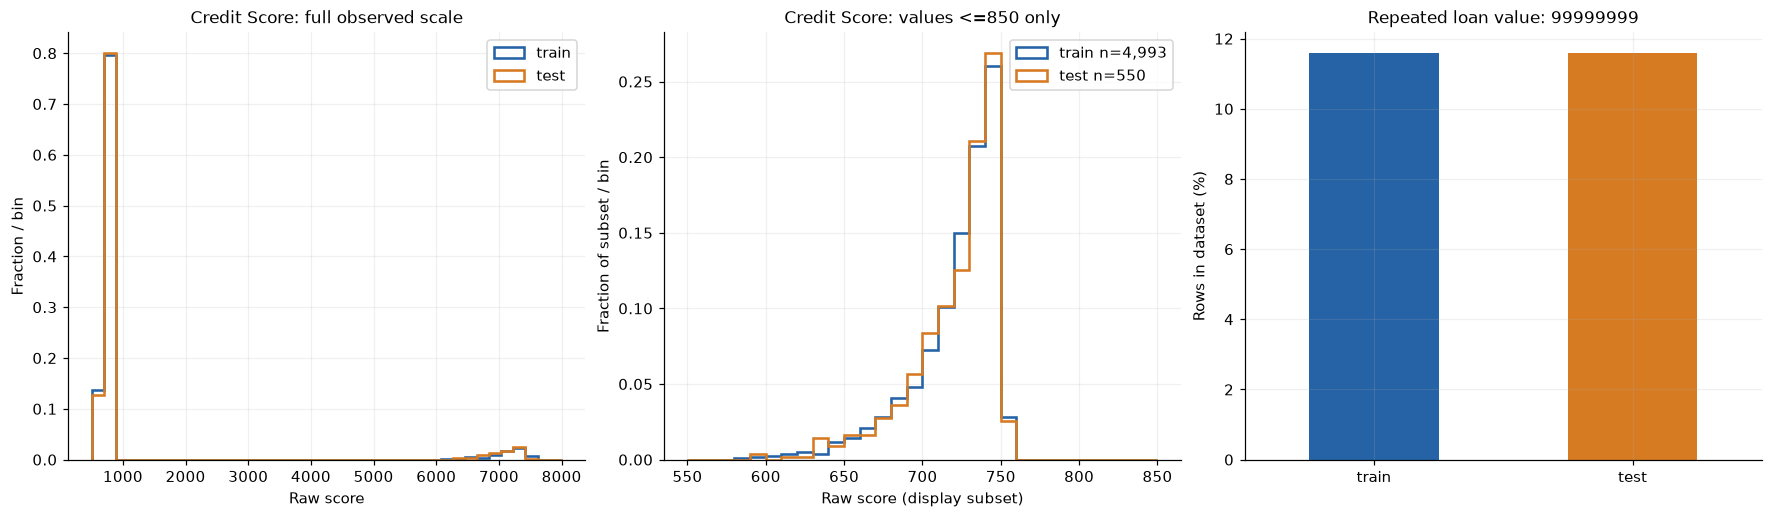

**Interpretation.** High scores occupy a separate range and are all multiples of ten. A mixed scale or data-export problem is plausible, but division by ten is not verified as the correct repair. The repeated loan value is far above other loan amounts and appears at the same frequency in both files (11.6% of rows), consistent with a possible sentinel or special-status code. This is a hypothesis, not a documented meaning. Confirm both fields with the data owner; do not replace, rescale or remove these observations automatically.

In [10]:
anomaly_rows = []
score_diagnostics = []
for name, frame in datasets.items():
    high = frame['Credit Score'].gt(850)
    sentinel = frame['Current Loan Amount'].eq(99999999)
    values = frame.loc[high, 'Credit Score']
    anomaly_rows.append({
        'dataset': name, 'score >850 n': int(high.sum()),
        'score >850 % of all rows': high.mean() * 100,
        'score >850 % of observed scores': high.sum() / frame['Credit Score'].notna().sum() * 100,
        'loan =99999999 n': int(sentinel.sum()),
        'loan =99999999 % of all rows': sentinel.mean() * 100,
        'both flags n': int((high & sentinel).sum()),
    })
    score_diagnostics.append({
        'dataset': name, 'high-score minimum': values.min(), 'high-score maximum': values.max(),
        'all high scores divisible by 10': bool(values.mod(10).eq(0).all()),
        'hypothetical /10 minimum': values.div(10).min(),
        'hypothetical /10 maximum': values.div(10).max(),
        'maximum loan excluding 99999999': frame.loc[~sentinel, 'Current Loan Amount'].max(),
    })
anomaly_audit = pd.DataFrame(anomaly_rows).set_index('dataset')
show_table(anomaly_audit, 'Anomaly counts and explicitly defined denominators')
show_table(pd.DataFrame(score_diagnostics).set_index('dataset'), 'Scale and repeated-value diagnostics')
for name, frame in datasets.items():
    show_table(frame['Current Loan Amount'].value_counts().head(5).rename('rows').to_frame(),
               f'{name.title()}: five most frequent raw loan amounts')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), layout='constrained')
for name, frame in datasets.items():
    score = frame['Credit Score'].dropna()
    axes[0].hist(score, bins=np.linspace(500, 8000, 40), histtype='step', linewidth=1.7,
                 weights=np.full(len(score), 1 / len(score)), label=name, color=COLORS[name])
    regular = score[score.le(850)]
    axes[1].hist(regular, bins=np.linspace(550, 850, 31), histtype='step', linewidth=1.7,
                 weights=np.full(len(regular), 1 / len(regular)), label=f'{name} n={len(regular):,}', color=COLORS[name])
axes[0].set(title='Credit Score: full observed scale', xlabel='Raw score', ylabel='Fraction / bin')
axes[1].set(title='Credit Score: values <=850 only', xlabel='Raw score (display subset)', ylabel='Fraction of subset / bin')
anomaly_audit['loan =99999999 % of all rows'].plot.bar(ax=axes[2], color=[COLORS['train'], COLORS['test']])
axes[2].set(title='Repeated loan value: 99999999', ylabel='Rows in dataset (%)', xlabel='')
axes[2].tick_params(axis='x', rotation=0)
axes[0].legend(); axes[1].legend()
plt.show()
note('High scores occupy a separate range and are all multiples of ten. A mixed scale or '
     'data-export problem is plausible, but division by ten is not verified as the correct repair. '
     'The repeated loan value is far above other loan amounts and appears at the same frequency '
     'in both files (11.6% of rows), consistent with a possible sentinel or special-status code. '
     'This is a hypothesis, not a documented meaning. Confirm both fields with the data owner; '
     'do not replace, rescale or remove these observations automatically.')

In [11]:
flags = {
    'Credit Score >850': X_train['Credit Score'].gt(850),
    'Current Loan Amount =99999999': X_train['Current Loan Amount'].eq(99999999),
}
flag_target_tables = []
for label, flag in flags.items():
    temp = pd.DataFrame({'flag': flag, 'target': y_train})
    stats = temp.groupby('flag')['target'].agg(n='size', class_1_n='sum', class_1_rate='mean')
    stats['flag definition'] = label
    flag_target_tables.append(stats.reset_index().set_index(['flag definition', 'flag']))
flag_target_audit = pd.concat(flag_target_tables)
show_table(flag_target_audit, 'Train only: target association with anomaly flags (False includes missing scores)')
show_table(X_train['Maximum Open Credit'].nlargest(5).rename('raw Maximum Open Credit').to_frame(),
           'Train only: largest credit-limit observations, source row indices retained')
note('All 357 high-score training rows have class 1; all 783 training rows with loan amount '
     '99999999 have class 0. This unusually clean separation may encode collection artifacts, '
     'status information or leakage. The table does not prove causality or genuine forecasting value. '
     'Confirm when and how each field was recorded relative to the outcome before modeling. '
     'Test labels were not used to check or reproduce these associations.')

**Train only: target association with anomaly flags (False includes missing scores)**

n  class_1_n  class_1_rate
flag definition               flag                                
Credit Score >850             False  6393       1568         0.245
                              True    357        357         1.000
Current Loan Amount =99999999 False  5967       1925         0.323
                              True    783          0         0.000

**Train only: largest credit-limit observations, source row indices retained**

,raw Maximum Open Credit
3823,"1,304,726,170.000"
353,"265,512,874.000"
3709,"26,406,996.000"
4809,"26,343,328.000"
3370,"21,372,428.000"


**Interpretation.** All 357 high-score training rows have class 1; all 783 training rows with loan amount 99999999 have class 0. This unusually clean separation may encode collection artifacts, status information or leakage. The table does not prove causality or genuine forecasting value. Confirm when and how each field was recorded relative to the outcome before modeling. Test labels were not used to check or reproduce these associations.

### 6. Class balance and relationships (training data only)
All outcome comparisons below use the original training target. Class-1 shares are empirical rates; small groups give unstable rates, so group sizes are shown. Missing values are kept as their own category where applicable. Numeric plots skip only the missing values of the feature being shown and print the group sizes on each plot.

**Training class balance**

,n,% of train
Credit Default,,
0,4825,71.481
1,1925,28.519


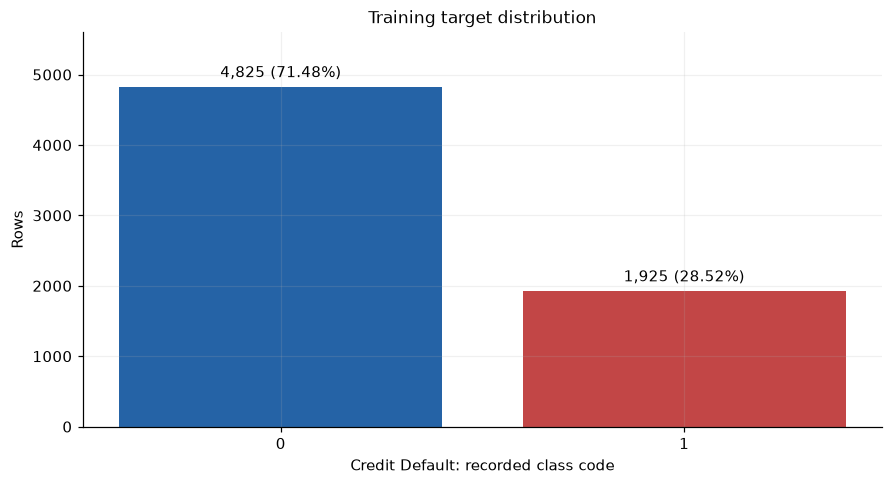

**Interpretation.** Class 1 contains 1,925 / 6,750 rows (28.52%); the majority class is 0. Preserve this balance with a stratified training/validation split and report Precision, Recall and F1 rather than accuracy alone. This notebook performs no split or evaluation.

In [12]:
target_balance = y_train.value_counts().sort_index().rename('n').to_frame()
target_balance['% of train'] = target_balance['n'].div(len(y_train)).mul(100)
show_table(target_balance, 'Training class balance')
fig, ax = plt.subplots(figsize=(8, 4.3), layout='constrained')
bars = ax.bar([str(v) for v in target_balance.index], target_balance['n'], color=[COLORS[0], COLORS[1]])
ax.bar_label(bars, labels=[f'{row["n"]:,.0f} ({row["% of train"]:.2f}%)'
                         for _, row in target_balance.iterrows()], padding=4)
ax.set(title='Training target distribution', xlabel='Credit Default: recorded class code', ylabel='Rows', ylim=(0, 5600))
plt.show()
class_1_rate = y_train.mean()
note(f'Class 1 contains {int(y_train.sum()):,} / {len(y_train):,} rows ({class_1_rate:.2%}); '
     'the majority class is 0. Preserve this balance with a stratified training/validation split '
     'and report Precision, Recall and F1 rather than accuracy alone. This notebook performs no split or evaluation.')

**Train only: numeric summaries by target class (raw values)**

group rows  observed n  missing n  \
feature                      class                                      
Annual Income                0            4825        3908        917   
                             1            1925        1442        483   
Tax Liens                    0            4825        4825          0   
                             1            1925        1925          0   
Number of Open Accounts      0            4825        4825          0   
                             1            1925        1925          0   
Years of Credit History      0            4825        4825          0   
                             1            1925        1925          0   
Maximum Open Credit          0            4825        4825          0   
                             1            1925        1925          0   
Number of Credit Problems    0            4825        4825          0   
                             1            1925        1925          0   
Months since last delinquent 0            4825        2175       2650   
                             1            1925         900       1025   
Bankruptcies                 0            4825        4817          8   
                             1            1925        1921          4   
Current Loan Amount          0            4825        4825          0   
                             1            1925        1925          0   
Current Credit Balance       0            4825        4825          0   
                             1            1925        1925          0   
Monthly Debt                 0            4825        4825          0   
                             1            1925        1925          0   
Credit Score                 0            4825        3908        917   
                             1            1925        1442        483   

                                             mean        median          Q1  \
feature                      class                                            
Annual Income                0      1,418,905.249 1,226,991.500 868,409.250   
                             1      1,231,813.653 1,063,753.000 774,663.250   
Tax Liens                    0              0.027         0.000       0.000   
                             1              0.036         0.000       0.000   
Number of Open Accounts      0             11.037        10.000       8.000   
                             1             11.361        11.000       8.000   
Years of Credit History      0             18.415        17.100      13.700   
                             1             18.100        16.700      13.100   
Maximum Open Credit          0      1,034,237.559   490,710.000 290,136.000   
                             1        580,704.983   447,348.000 257,774.000   
Number of Credit Problems    0              0.166         0.000       0.000   
                             1              0.179         0.000       0.000   
Months since last delinquent 0             34.763        32.000      17.000   
                             1             34.677        32.000      15.000   
Bankruptcies                 0              0.119         0.000       0.000   
                             1              0.118         0.000       0.000   
Current Loan Amount          0     16,479,461.432   314,842.000 179,080.000   
                             1        327,177.086   291,214.000 181,434.000   
Current Credit Balance       0        292,077.919   207,423.000 112,917.000   
                             1        280,695.765   209,589.000 112,461.000   
Monthly Debt                 0         18,152.318    15,981.000   9,885.000   
                             1         18,809.060    16,473.000  10,686.000   
Credit Score                 0            723.731       732.000     713.000   
                             1          2,297.174       730.000     704.000   

                                              Q3  
feature                      cl

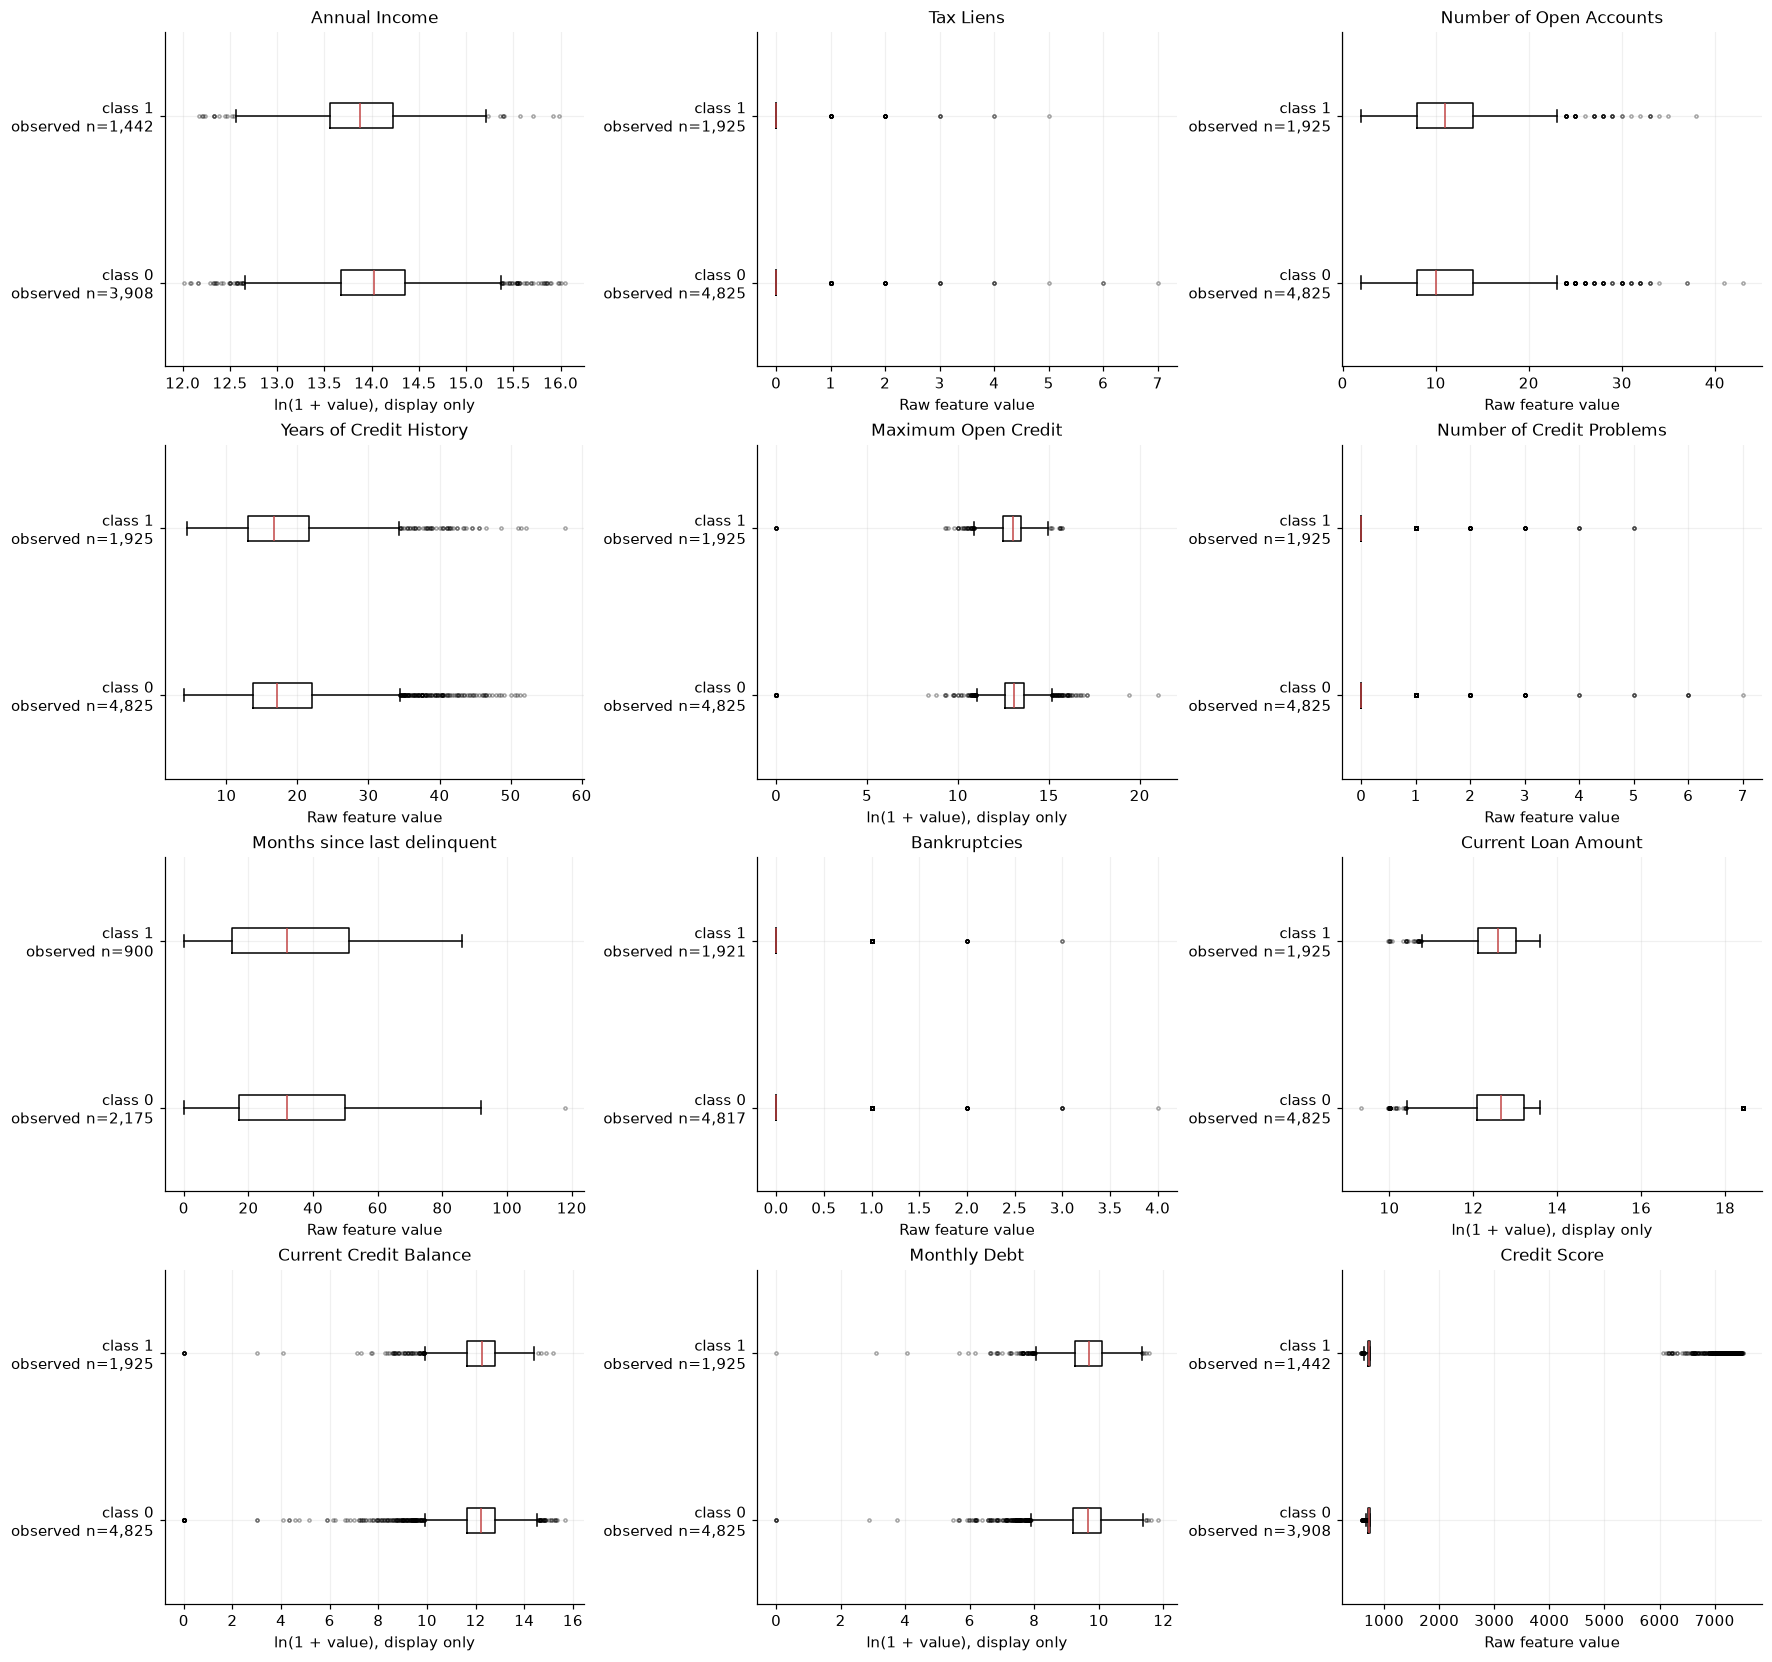

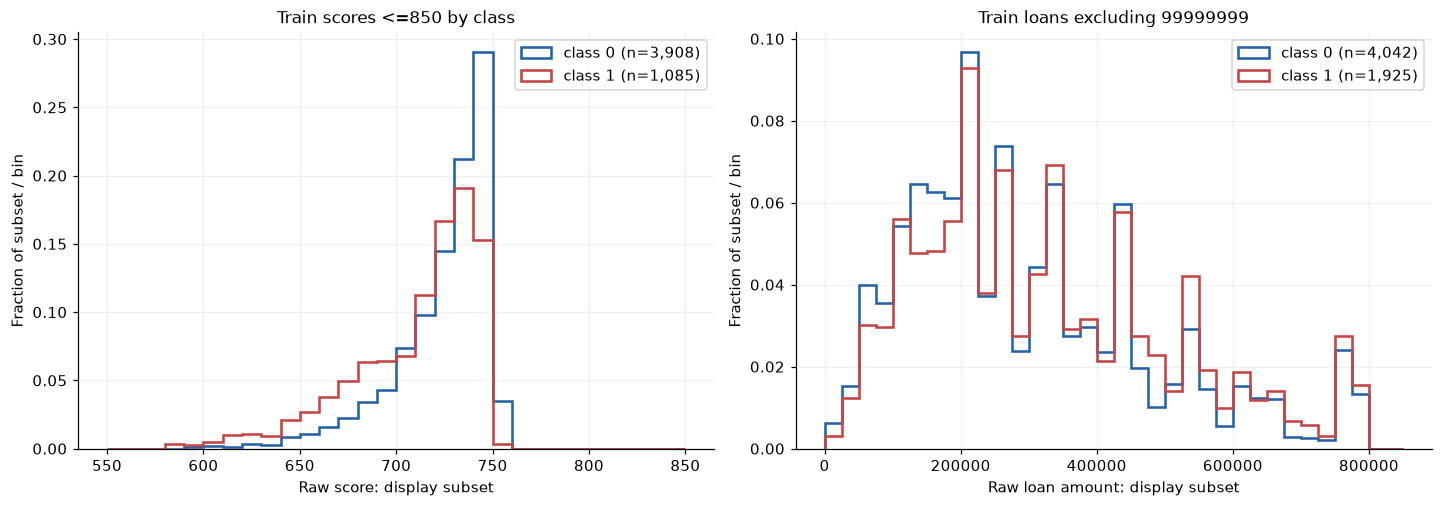

**Interpretation.** Group means and raw ranges for Credit Score and Current Loan Amount are strongly affected by the anomalous values. Medians, quartiles and the explicitly labeled display subsets help separate central patterns from those artifacts. The subset plots are conditional summaries, not cleaned datasets; all rows remain in memory and in the source. Distribution overlap and class-size differences prevent treating these plots as validated predictors.

In [13]:
numeric_target_rows = []
for col in numeric_cols:
    for cls in [0, 1]:
        values = X_train.loc[y_train.eq(cls), col]
        numeric_target_rows.append({
            'feature': col, 'class': cls, 'group rows': len(values), 'observed n': int(values.notna().sum()),
            'missing n': int(values.isna().sum()), 'mean': values.mean(), 'median': values.median(),
            'Q1': values.quantile(0.25), 'Q3': values.quantile(0.75),
        })
show_table(pd.DataFrame(numeric_target_rows).set_index(['feature', 'class']),
           'Train only: numeric summaries by target class (raw values)')

fig, axes = plt.subplots(4, 3, figsize=(16, 15), layout='constrained')
for ax, col in zip(axes.flat, numeric_cols):
    by_class = [X_train.loc[y_train.eq(cls), col].dropna() for cls in [0, 1]]
    use_log = col in money_cols
    plotted = [np.log1p(s).to_numpy() if use_log else s.to_numpy() for s in by_class]
    ax.boxplot(plotted, tick_labels=[f'class {cls}\nobserved n={len(s):,}' for cls, s in zip([0, 1], by_class)],
               orientation='horizontal', flierprops={'markersize': 2, 'alpha': 0.35}, medianprops={'color': '#c24646'})
    ax.set(title=wrap(col, 30), xlabel='ln(1 + value), display only' if use_log else 'Raw feature value')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout='constrained')
for cls in [0, 1]:
    mask = y_train.eq(cls)
    score = X_train.loc[mask & X_train['Credit Score'].le(850), 'Credit Score'].dropna()
    loan = X_train.loc[mask & X_train['Current Loan Amount'].ne(99999999), 'Current Loan Amount'].dropna()
    for ax, values, edges in [(axes[0], score, np.linspace(550, 850, 31)),
                               (axes[1], loan, np.linspace(0, 850000, 35))]:
        ax.hist(values, bins=edges, weights=np.full(len(values), 1 / len(values)), histtype='step',
                 linewidth=1.7, color=COLORS[cls], label=f'class {cls} (n={len(values):,})')
axes[0].set(title='Train scores <=850 by class', xlabel='Raw score: display subset', ylabel='Fraction of subset / bin')
axes[1].set(title='Train loans excluding 99999999', xlabel='Raw loan amount: display subset', ylabel='Fraction of subset / bin')
for ax in axes: ax.legend()
plt.show()
note('Group means and raw ranges for Credit Score and Current Loan Amount are strongly affected by '
     'the anomalous values. Medians, quartiles and the explicitly labeled display subsets help '
     'separate central patterns from those artifacts. The subset plots are conditional summaries, '
     'not cleaned datasets; all rows remain in memory and in the source. Distribution overlap '
     'and class-size differences prevent treating these plots as validated predictors.')

**Train only: class-1 share by Home Ownership, with denominators**

,n,class_1_n,class_1_rate,class_1_%,small group (<1% train)
category,,,,,
Have Mortgage,10,1,0.100,10.000,True
Home Mortgage,3279,840,0.256,25.618,False
Own Home,579,174,0.301,30.052,False
Rent,2882,910,0.316,31.575,False


**Train only: class-1 share by Years in current job, with denominators**

,n,class_1_n,class_1_rate,class_1_%,small group (<1% train)
category,,,,,
9 years,233,62,0.266,26.609,False
3 years,566,153,0.270,27.032,False
8 years,309,84,0.272,27.184,False
2 years,639,177,0.277,27.700,False
10+ years,2098,589,0.281,28.074,False
< 1 year,501,141,0.281,28.144,False
1 year,437,123,0.281,28.146,False
7 years,355,100,0.282,28.169,False
4 years,426,120,0.282,28.169,False


**Train only: class-1 share by Purpose, with denominators**

,n,class_1_n,class_1_rate,class_1_%,small group (<1% train)
category,,,,,
educational expenses,10,1,0.100,10.000,True
vacation,6,1,0.167,16.667,True
moving,10,2,0.200,20.000,True
major purchase,39,9,0.231,23.077,True
take a trip,33,8,0.242,24.242,True
buy a car,86,21,0.244,24.419,False
buy house,33,9,0.273,27.273,True
home improvements,374,103,0.275,27.540,False
debt consolidation,5326,1492,0.280,28.014,False


**Train only: class-1 share by Term, with denominators**

,n,class_1_n,class_1_rate,class_1_%,small group (<1% train)
category,,,,,
Short Term,5004,1174,0.235,23.461,False
Long Term,1746,751,0.430,43.013,False


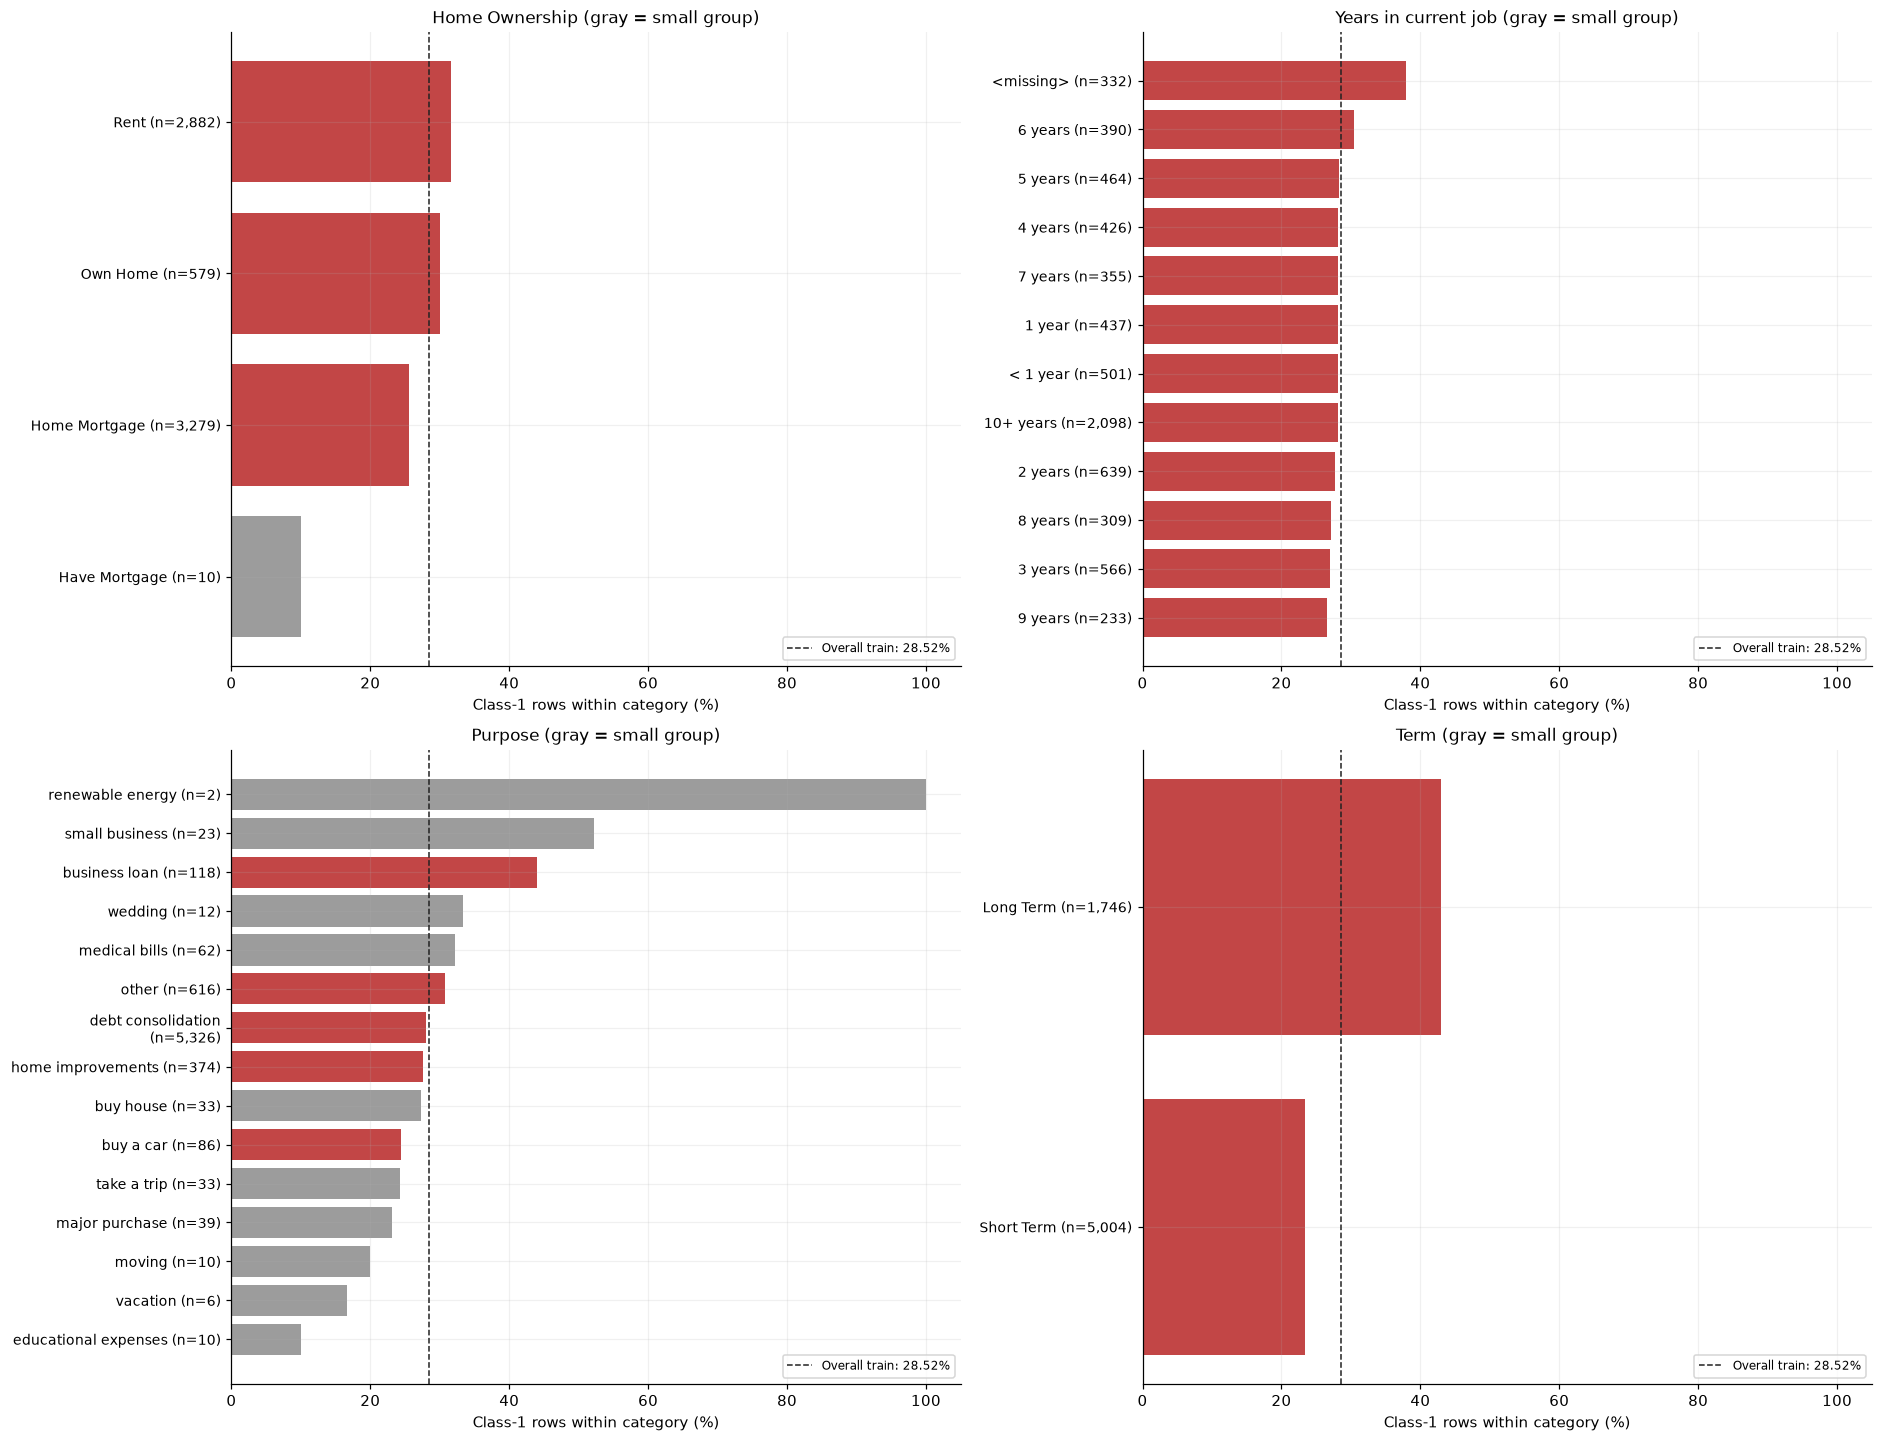

**Interpretation.** Long Term has a class-1 share of 43.01% (n=1,746), versus 23.46% for Short Term (n=5,004). This is an unadjusted association, not an effect of term length. Rare Purpose and housing levels can show extreme percentages based on very few rows; do not rank categories by rate without considering their denominators or claim significance from these descriptive comparisons.

In [14]:
category_target_tables = {}
for col in categorical_cols:
    temp = pd.DataFrame({'category': X_train[col].fillna('<missing>'), 'target': y_train})
    stats = temp.groupby('category')['target'].agg(n='size', class_1_n='sum', class_1_rate='mean')
    stats['class_1_%'] = stats['class_1_rate'] * 100
    stats['small group (<1% train)'] = stats['n'].lt(0.01 * len(X_train))
    stats = stats.sort_values(['class_1_rate', 'n'])
    category_target_tables[col] = stats
    show_table(stats, f'Train only: class-1 share by {col}, with denominators')

fig, axes = plt.subplots(2, 2, figsize=(17, 13), layout='constrained')
for ax, col in zip(axes.flat, categorical_cols):
    stats = category_target_tables[col]
    positions = np.arange(len(stats))
    colors = [COLORS[1] if n >= 0.01 * len(X_train) else '#9c9c9c' for n in stats['n']]
    ax.barh(positions, stats['class_1_%'], color=colors)
    ax.set_yticks(positions, [wrap(f'{level} (n={row["n"]:,})', 27) for level, row in stats.iterrows()], fontsize=9)
    ax.axvline(class_1_rate * 100, color='#222222', linestyle='--', linewidth=1,
               label=f'Overall train: {class_1_rate:.2%}')
    ax.set(title=col + ' (gray = small group)', xlabel='Class-1 rows within category (%)', xlim=(0, 105))
    ax.legend(fontsize=8, loc='lower right')
plt.show()
term_rates = category_target_tables['Term']
note(f'Long Term has a class-1 share of {term_rates.loc["Long Term", "class_1_rate"]:.2%} '
     f'(n={term_rates.loc["Long Term", "n"]:,}), versus '
     f'{term_rates.loc["Short Term", "class_1_rate"]:.2%} for Short Term '
     f'(n={term_rates.loc["Short Term", "n"]:,}). '
     'This is an unadjusted association, not an effect of term length. Rare Purpose and housing '
     'levels can show extreme percentages based on very few rows; do not rank categories by rate '
     'without considering their denominators or claim significance from these descriptive comparisons.')

**Train only: target share for observed and missing feature groups**

n  class_1_n  class_1_rate
feature                      missing                                   
Annual Income                False   5,350.000  1,442.000         0.270
                             True    1,400.000    483.000         0.345
Years in current job         False   6,418.000  1,799.000         0.280
                             True      332.000    126.000         0.380
Months since last delinquent False   3,075.000    900.000         0.293
                             True    3,675.000  1,025.000         0.279
Bankruptcies                 False   6,738.000  1,921.000         0.285
                             True       12.000      4.000         0.333
Credit Score                 False   5,350.000  1,442.000         0.270
                             True    1,400.000    483.000         0.345

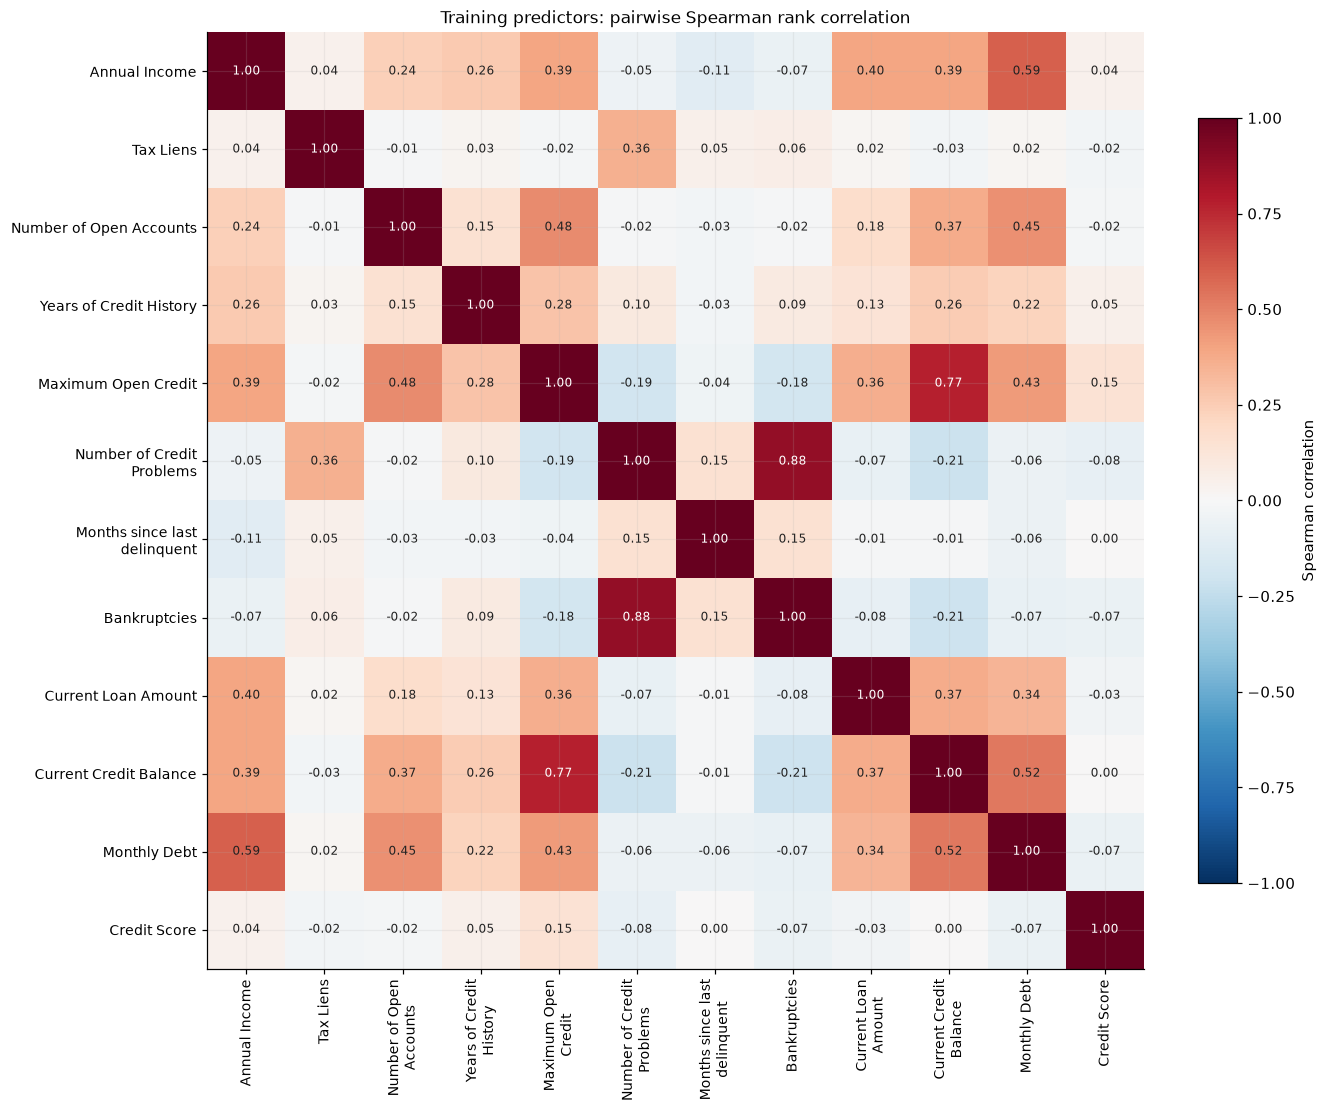

**Interpretation.** Missingness-group rates make potential missing-indicator features reviewable, but they do not explain why values are absent. Income and score indicators would be identical on these files. Spearman correlation describes monotonic predictor relationships using pairwise observed values, so sample sizes can differ between cells. Correlation is not causality, and anomalous values remain present even in this rank-based diagnostic.

In [15]:
missing_target_rows = []
for col in missing_cols:
    temp = pd.DataFrame({'missing': X_train[col].isna(), 'target': y_train})
    stats = temp.groupby('missing')['target'].agg(n='size', class_1_n='sum', class_1_rate='mean')
    for missing, row in stats.iterrows():
        missing_target_rows.append({'feature': col, 'missing': missing, **row.to_dict()})
show_table(pd.DataFrame(missing_target_rows).set_index(['feature', 'missing']),
           'Train only: target share for observed and missing feature groups')

corr = X_train[numeric_cols].corr(method='spearman')
fig, ax = plt.subplots(figsize=(12, 10), layout='constrained')
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(numeric_cols)), [wrap(c, 17) for c in numeric_cols], rotation=90, fontsize=9)
ax.set_yticks(range(len(numeric_cols)), [wrap(c, 24) for c in numeric_cols], fontsize=9)
ax.set_title('Training predictors: pairwise Spearman rank correlation')
for i in range(len(numeric_cols)):
    for j in range(len(numeric_cols)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8,
                color='white' if abs(corr.iloc[i, j]) > 0.65 else '#222222')
fig.colorbar(im, ax=ax, fraction=0.035, label='Spearman correlation')
plt.show()
note('Missingness-group rates make potential missing-indicator features reviewable, but they do '
     'not explain why values are absent. Income and score indicators would be identical on these '
     'files. Spearman correlation describes monotonic predictor relationships using pairwise '
     'observed values, so sample sizes can differ between cells. Correlation is not causality, '
     'and anomalous values remain present even in this rank-based diagnostic.')

### 7. Evidence and recommendations for the team
The recommendations below are provisional and were implemented in part 2. Part 2 owns the training/validation split, the fitted preprocessing pipeline and the baseline; part 3 owns additional models, metric comparison and error analysis.

In [16]:
recommendations = [
    ('Substantial missingness',
     f'Delinquency months missing: {X_train["Months since last delinquent"].isna().sum():,}/6,750 train; '
     f'{X_test["Months since last delinquent"].isna().sum():,}/750 test.',
     'Confirm the meaning of missingness. Compare training-fitted imputation and a missing indicator; do not drop test rows.'),
    ('Income and score co-missingness',
     f'Identical masks: {co_missing.loc["train", "both missing"]:,} train and {co_missing.loc["test", "both missing"]:,} test rows missing both.',
     'Investigate shared collection logic. Avoid treating two identical missing indicators as independent information.'),
    ('Other missing predictors',
     f'Employment tenure missing: {X_train["Years in current job"].isna().sum():,} train; '
     f'Bankruptcies missing: {X_train["Bankruptcies"].isna().sum():,} train.',
     'Consider a missing tenure level and count-aware bankruptcy imputation within the fitted pipeline.'),
    ('Categorical encoding and rare levels',
     f'{len(categorical_cols)} categorical predictors; Have Mortgage n={category_tables["Home Ownership"].loc["Have Mortgage", "train n"]}; no test-only levels.',
     'Use unknown-safe encoding. Confirm mortgage aliases; learn any rare-level grouping on the training fold only. Encode tenure order only if justified.'),
    ('Mixed score-scale hypothesis',
     f'Score >850: {anomaly_audit.loc["train", "score >850 n"]:,} train, '
     f'{anomaly_audit.loc["test", "score >850 n"]:,} test; all 357 high-score train rows are class 1.',
     'Confirm score scale and measurement timing. Investigate leakage before considering /10 repair or an anomaly flag; compare only within training validation.'),
    ('Possible repeated-value sentinel',
     'Loan amount 99999999: 783 train and 87 test; all 783 training cases are class 0.',
     'Request source semantics and timing. Consider flagged/missing treatment only after confirmation; do not replace with zero or delete rows.'),
    ('Long tails and discrete IQR limitations',
     f'Maximum Open Credit reaches {X_train["Maximum Open Credit"].max():,.0f} in train; '
     f'zero-IQR features: {", ".join(zero_iqr)}.',
     'Review extreme values with the source. Evaluate log transforms or robust scaling for sensitive models; tree models may not need scaling. Fit any fences/scalers on the training fold.'),
    ('Class imbalance and uncertain business mapping',
     f'Class 1: {int(y_train.sum()):,}/6,750 ({class_1_rate:.2%}); code meaning is not formally documented.',
     'Confirm label mapping. Use stratification, Precision/Recall/F1 and confusion matrices; choose thresholds using validation, not test labels.'),
    ('Outcome associations need validation',
     f'Long Term class-1 share {term_rates.loc["Long Term", "class_1_rate"]:.2%} vs '
     f'Short Term {term_rates.loc["Short Term", "class_1_rate"]:.2%}; rare categories have small n.',
     'Treat findings as hypotheses. Validate performance and stability after a split; do not infer causal effects or use full-train target-rate encoding.'),
    ('Matching schemas and row preservation',
     'Both source files have 17 columns; both predictor schemas have 16 matching columns; test has 750 rows.',
     'Keep all test rows and their order. Freeze model/processing decisions before final evaluation; test-target access remains outside this EDA.'),
]
handoff = pd.DataFrame(recommendations, columns=['Observation', 'Evidence', 'Recommendation'])
# Wrapping long text keeps the complete handoff readable in notebook viewers.
display(Markdown('**Observation → evidence → recommendation**'))
handoff_html = handoff.to_html(index=False, escape=True, border=0)
handoff_html = handoff_html.replace('<table ', '<table style="table-layout:fixed; width:100%;" ')
handoff_html = handoff_html.replace('<td>', '<td style="white-space:normal; overflow-wrap:anywhere; text-align:left; vertical-align:top; padding:8px;">')
display({'text/html': handoff_html, 'text/plain': handoff.to_string(index=False)}, raw=True)
note('The most urgent unresolved questions are the high-score scale, the repeated loan value, '
     'the time at which those fields were captured, and the label-code meaning. These affect '
     'whether a model learns credit behavior or artifacts. No preprocessing parameters or models '
     'have been fitted. Recompute any selected transformation parameters within the training '
     'portion (and within each cross-validation fold), then apply the fitted pipeline to validation/test.')

**Observation → evidence → recommendation**

Observation,Evidence,Recommendation
Substantial missingness,"Delinquency months missing: 3,675/6,750 train; 406/750 test.",Confirm the meaning of missingness. Compare training-fitted imputation and a missing indicator; do not drop test rows.
Income and score co-missingness,"Identical masks: 1,400 train and 157 test rows missing both.",Investigate shared collection logic. Avoid treating two identical missing indicators as independent information.
Other missing predictors,Employment tenure missing: 332 train; Bankruptcies missing: 12 train.,Consider a missing tenure level and count-aware bankruptcy imputation within the fitted pipeline.
Categorical encoding and rare levels,4 categorical predictors; Have Mortgage n=10; no test-only levels.,Use unknown-safe encoding. Confirm mortgage aliases; learn any rare-level grouping on the training fold only. Encode tenure order only if justified.
Mixed score-scale hypothesis,"Score >850: 357 train, 43 test; all 357 high-score train rows are class 1.",Confirm score scale and measurement timing. Investigate leakage before considering /10 repair or an anomaly flag; compare only within training validation.
Possible repeated-value sentinel,Loan amount 99999999: 783 train and 87 test; all 783 training cases are class 0.,Request source semantics and timing. Consider flagged/missing treatment only after confirmation; do not replace with zero or delete rows.
Long tails and discrete IQR limitations,"Maximum Open Credit reaches 1,304,726,170 in train; zero-IQR features: Tax Liens, Number of Credit Problems, Bankruptcies.",Review extreme values with the source. Evaluate log transforms or robust scaling for sensitive models; tree models may not need scaling. Fit any fences/scalers on the training fold.
Class imbalance and uncertain business mapping,"Class 1: 1,925/6,750 (28.52%); code meaning is not formally documented.","Confirm label mapping. Use stratification, Precision/Recall/F1 and confusion matrices; choose thresholds using validation, not test labels."
Outcome associations need validation,Long Term class-1 share 43.01% vs Short Term 23.46%; rare categories have small n.,Treat findings as hypotheses. Validate performance and stability after a split; do not infer causal effects or use full-train target-rate encoding.
Matching schemas and row preservation,Both source files have 17 columns; both predictor schemas have 16 matching columns; test has 750 rows.,Keep all test rows and their order. Freeze model/processing decisions before final evaluation; test-target access remains outside this EDA.


**Interpretation.** The most urgent unresolved questions are the high-score scale, the repeated loan value, the time at which those fields were captured, and the label-code meaning. These affect whether a model learns credit behavior or artifacts. No preprocessing parameters or models have been fitted. Recompute any selected transformation parameters within the training portion (and within each cross-validation fold), then apply the fitted pipeline to validation/test.

In [17]:
# Re-read the sources to verify both in-memory and on-disk preservation.
pd.testing.assert_frame_equal(train_raw, train_snapshot)
pd.testing.assert_frame_equal(test_raw, test_snapshot)
pd.testing.assert_frame_equal(X_train, train_raw.drop(columns=[TARGET]))
pd.testing.assert_frame_equal(X_test, test_raw.drop(columns=[TARGET]))
pd.testing.assert_series_equal(y_train, train_raw[TARGET])
with ZipFile(archive_path) as archive:
    pd.testing.assert_frame_equal(train_raw, pd.read_csv(archive.open('project-5/train_data.csv')))
    pd.testing.assert_frame_equal(test_raw, pd.read_csv(archive.open('project-5/test_data.csv')))
assert len(X_test) == 750 and X_test.index.equals(test_snapshot.index)
assert TARGET not in X_test.columns and TARGET not in X_train.columns
assert train_raw.shape == (6750, 17) and test_raw.shape == (750, 17)
archive_sha256_after = hashlib.sha256(archive_path.read_bytes()).hexdigest()
assert archive_sha256_before == archive_sha256_after
report('ALL INTEGRITY CHECKS PASSED')
report('Source shapes: train =', train_raw.shape, '; test =', test_raw.shape)
report('Preserved test rows and order:', len(X_test))
report('EDA predictors: train =', X_train.shape, '; test =', X_test.shape)
report('Archive SHA256 after:', archive_sha256_after)
report('Archive unchanged:', archive_sha256_before == archive_sha256_after)
report('No source values changed; no preprocessing, splitting or model training performed.')

ALL INTEGRITY CHECKS PASSED

Source shapes: train = (6750, 17) ; test = (750, 17)

Preserved test rows and order: 750

EDA predictors: train = (6750, 16) ; test = (750, 16)

Archive SHA256 after: 52b39c9c3a85516f3979fb233080000d4baac655366a87cfa8cab8f82bd0f206

Archive unchanged: True

No source values changed; no preprocessing, splitting or model training performed.

<a id="part-2"></a>

# Part 2. Preprocessing, split and baseline — Abylay Latiyev

This part turns the EDA recommendations into a fitted preprocessing pipeline, splits the original training file into a training part and a validation part, and trains the baseline model.

**Contents:** 1. Load data · 2. Preprocessing decisions · 3. Train/validation split · 4. Fit and inspect the pipeline · 5. Baseline model · 6. Sensitivity check · 7. Training-only parameter search · 8. Outputs for part 3.

**Evaluation boundary:** test labels are never loaded in this part. Every fitted parameter (medians, scaler statistics, category levels) is learned only on the training part inside `Pipeline.fit`. Parameter selection uses training-only cross-validation, and the validation part is used for reporting. Part 1 already explored the full training target, including these validation rows, so validation is not fully blind. All 750 test rows are kept in their original order.

In [18]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

import credit_pipeline as cp

pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
OUT = Path('artifacts') / 'participant2'
OUT.mkdir(parents=True, exist_ok=True)

def show(frame, caption):
    display(Markdown(f'**{caption}**'))
    display(frame)

def note(text):
    display(Markdown('**Interpretation.** ' + text))

display(Markdown(f'pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__}'))

pandas 3.1.1 | numpy 2.5.4 | scikit-learn 1.9.1

### 1. Load data
`cp.load_data()` reads both CSV files straight from the archive and excludes the target while reading the
test file, so the test labels cannot be used by accident.

In [19]:
X_full, y_full, X_test = cp.load_data()
assert X_full.shape == (6750, 16) and X_test.shape == (750, 16)
assert cp.TARGET not in X_test.columns
show(pd.DataFrame({'rows': [len(X_full), len(X_test)], 'predictors': [X_full.shape[1], X_test.shape[1]],
                   'labels loaded': ['yes', 'no']}, index=['train file', 'test file']),
     'Loaded data')

**Loaded data**

,rows,predictors,labels loaded
train file,6750,16,yes
test file,750,16,no


### 2. Preprocessing decisions (from the EDA)
Each step answers a specific EDA finding. Stateless row-wise fixes live in `DomainCleaner`;
everything that learns from data (imputation, scaling, encoding) is fitted on the training part only.

| EDA finding | Decision in the pipeline | Fitted? |
|---|---|---|
| `Credit Score` > 850 in 357 train rows (6060–7510, all divisible by 10) | divide by 10 and keep `score_scale_flag` | no |
| `Current Loan Amount` = 99999999 in 783 train rows | treat as unknown (NaN → median) and keep `loan_sentinel_flag` | median: yes |
| `Annual Income` and `Credit Score` missing in exactly the same 1,400 rows | median imputation + **one** shared indicator `income_score_missing` | median: yes |
| `Months since last delinquent` missing in 54% of rows | median imputation + `delinquent_missing` indicator | median: yes |
| `Years in current job` stored as text, 332 missing | ordinal 0–10, median imputation + `tenure_missing` | median: yes |
| `Bankruptcies` missing in 12 rows | median imputation (count-aware, median is 0) | median: yes |
| Long right tails in monetary columns | `log1p` before scaling (linear model) | no |
| Different numeric scales | `StandardScaler` | yes |
| 3 nominal categoricals, rare levels (e.g. `Have Mortgage` n=10) | one-hot, levels with < 20 train rows grouped as infrequent, unknown-safe | yes |
| 28.5% class 1 | stratified split, `class_weight='balanced'`, report Precision / Recall / F1 | — |
| Extreme values (e.g. `Maximum Open Credit`) | no rows deleted, no clipping; log transform reduces their leverage | — |

**Open question carried over from the EDA:** the two anomaly flags separate the classes almost
perfectly in train (all score > 850 rows are class 1, all loan = 99999999 rows are class 0).
We keep them in the baseline because the information is already present in the raw values,
but section 6 measures how much of the score depends on them.

### 3. Train/validation split
Stratified 80/20 split of the original training file with `random_state=42`. The row indices are saved to `artifacts/participant2/split_indices.csv`, so part 3 evaluates every model on the same validation rows.

In [20]:
idx_tr, idx_va = cp.make_split(y_full)
X_tr, y_tr = X_full.loc[idx_tr], y_full.loc[idx_tr]
X_va, y_va = X_full.loc[idx_va], y_full.loc[idx_va]
assert idx_tr.intersection(idx_va).empty and len(idx_tr) + len(idx_va) == len(X_full)

split_table = pd.DataFrame({
    'rows': [len(y_tr), len(y_va), len(y_full)],
    'class 0': [int((y_tr == 0).sum()), int((y_va == 0).sum()), int((y_full == 0).sum())],
    'class 1': [int(y_tr.sum()), int(y_va.sum()), int(y_full.sum())],
    'class 1 %': [y_tr.mean() * 100, y_va.mean() * 100, y_full.mean() * 100],
}, index=['training part', 'validation part', 'original train file'])
show(split_table, 'Stratified split preserves the class balance')

split_df = pd.concat([pd.DataFrame({'row': idx_tr, 'part': 'train'}),
                      pd.DataFrame({'row': idx_va, 'part': 'valid'})]).sort_values('row')
split_df.to_csv(cp.SPLIT_FILE, index=False)
loaded_tr, loaded_va = cp.load_split()
assert loaded_tr.equals(idx_tr) and loaded_va.equals(idx_va)
note('Both parts keep the 28.5% share of class 1, so validation metrics are not distorted '
     'by a different class balance. The saved split reloads identically.')

**Stratified split preserves the class balance**

,rows,class 0,class 1,class 1 %
training part,5400,3860,1540,28.5185
validation part,1350,965,385,28.5185
original train file,6750,4825,1925,28.5185


**Interpretation.** Both parts keep the 28.5% share of class 1, so validation metrics are not distorted by a different class balance. The saved split reloads identically.

### 4. Fit and inspect the preprocessing pipeline
The preprocessor is fitted on the training part only, then applied unchanged to the validation part
and to the test predictors. We check that the output has no missing values and the same columns
everywhere.

In [21]:
pre = cp.build_preprocessor()
Z_tr = pre.fit_transform(X_tr)
Z_va = pre.transform(X_va)
Z_test = pre.transform(X_test)
feature_names = pre.named_steps['columns'].get_feature_names_out()

for name, Z in [('training part', Z_tr), ('validation part', Z_va), ('test predictors', Z_test)]:
    assert not np.isnan(Z).any(), name
    assert Z.shape[1] == len(feature_names)
show(pd.DataFrame({'rows': [Z_tr.shape[0], Z_va.shape[0], Z_test.shape[0]],
                   'features after preprocessing': [Z_tr.shape[1], Z_va.shape[1], Z_test.shape[1]],
                   'missing values': [int(np.isnan(Z).sum()) for Z in (Z_tr, Z_va, Z_test)]},
                  index=['training part', 'validation part', 'test predictors']),
     'Pipeline output: no missing values, identical feature space')

display(Markdown('**Output features (' + str(len(feature_names)) + '):** ' + ', '.join(f'`{f}`' for f in feature_names)))

**Pipeline output: no missing values, identical feature space**

,rows,features after preprocessing,missing values
training part,5400,34,0
validation part,1350,34,0
test predictors,750,34,0


**Output features (34):** `Annual Income`, `Maximum Open Credit`, `Current Loan Amount`, `Current Credit Balance`, `Monthly Debt`, `Tax Liens`, `Number of Open Accounts`, `Years of Credit History`, `Number of Credit Problems`, `Months since last delinquent`, `Bankruptcies`, `Credit Score`, `Years in current job`, `income_score_missing`, `delinquent_missing`, `tenure_missing`, `score_scale_flag`, `loan_sentinel_flag`, `Home Ownership_Home Mortgage`, `Home Ownership_Own Home`, `Home Ownership_Rent`, `Home Ownership_infrequent_sklearn`, `Purpose_business loan`, `Purpose_buy a car`, `Purpose_buy house`, `Purpose_debt consolidation`, `Purpose_home improvements`, `Purpose_major purchase`, `Purpose_medical bills`, `Purpose_other`, `Purpose_take a trip`, `Purpose_infrequent_sklearn`, `Term_Long Term`, `Term_Short Term`

**Training part: effect of the row-wise fixes**

,before,after DomainCleaner
Credit Score > 850,298.0000,0.0000
Loan = 99999999,632.0000,0.0000
Tenure missing (imputed later),263.0000,263.0000
max Credit Score,"7,510.0000",751.0000


**Imputation values (fitted on the training part only)**

,median learned on training part
Annual Income,"1,167,930.0000"
Maximum Open Credit,"478,170.0000"
Current Loan Amount,"265,298.0000"
Current Credit Balance,"208,050.0000"
Monthly Debt,"16,151.0000"
Tax Liens,0.0000
Number of Open Accounts,10.0000
Years of Credit History,17.0000
Number of Credit Problems,0.0000
Months since last delinquent,32.0000


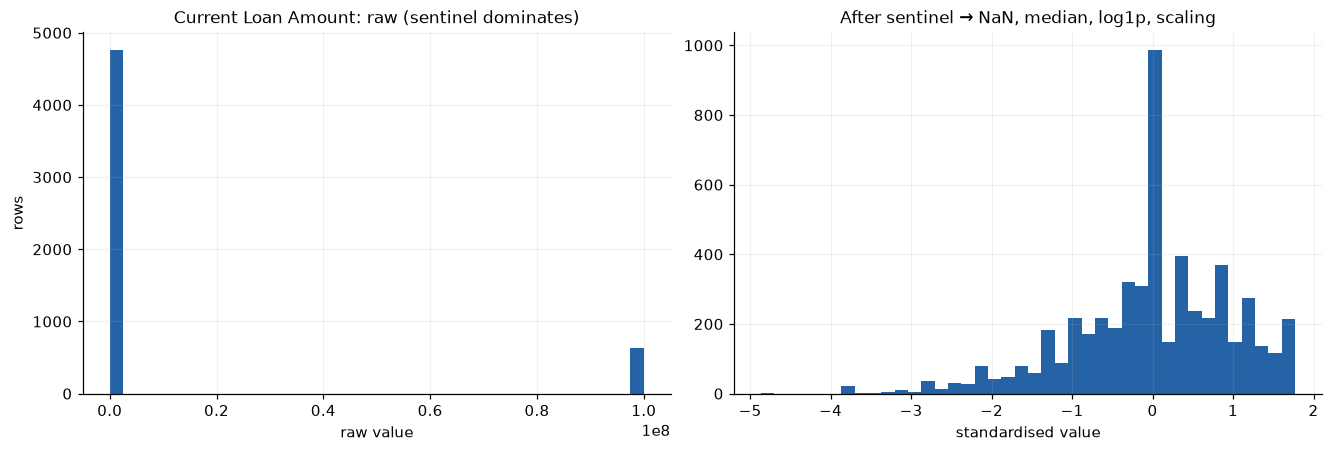

**Interpretation.** The score-scale and sentinel fixes are applied, tenure is numeric, and every missing value is filled with a median learned on the training part. The loan-amount sentinel no longer stretches the scale; its information is kept in `loan_sentinel_flag`.

In [22]:
clean_tr = cp.DomainCleaner().transform(X_tr)
check = pd.DataFrame({
    'before': [int(X_tr['Credit Score'].gt(850).sum()), int(X_tr['Current Loan Amount'].eq(cp.LOAN_SENTINEL).sum()),
               int(X_tr['Years in current job'].isna().sum()), X_tr['Credit Score'].max()],
    'after DomainCleaner': [int(clean_tr['Credit Score'].gt(850).sum()),
                            int(clean_tr['Current Loan Amount'].eq(cp.LOAN_SENTINEL).sum()),
                            int(clean_tr['Years in current job'].isna().sum()), clean_tr['Credit Score'].max()],
}, index=['Credit Score > 850', 'Loan = 99999999', 'Tenure missing (imputed later)', 'max Credit Score'])
show(check, 'Training part: effect of the row-wise fixes')

num = pre.named_steps['columns'].named_transformers_
medians = pd.Series(np.r_[num['money'][0].statistics_, num['numeric'][0].statistics_],
                    index=cp.MONEY_COLS + cp.OTHER_NUMERIC_COLS, name='median learned on training part')
show(medians.to_frame(), 'Imputation values (fitted on the training part only)')

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
raw = X_tr['Current Loan Amount']
axes[0].hist(raw, bins=40, color='#2563a6')
axes[0].set(title='Current Loan Amount: raw (sentinel dominates)', xlabel='raw value', ylabel='rows')
money_idx = list(feature_names).index('Current Loan Amount')
axes[1].hist(Z_tr[:, money_idx], bins=40, color='#2563a6')
axes[1].set(title='After sentinel → NaN, median, log1p, scaling', xlabel='standardised value')
plt.show()
note('The score-scale and sentinel fixes are applied, tenure is numeric, and every missing value '
     'is filled with a median learned on the training part. The loan-amount sentinel no longer '
     'stretches the scale; its information is kept in `loan_sentinel_flag`.')

### 5. Fixed reference baseline (reproducing the existing project)
**Fixed reference: logistic regression** (`class_weight='balanced'`, `max_iter=2000`). It is fast and interpretable, works on the scaled inputs the pipeline provides, and gives part 3 a reference point. A `DummyClassifier` that always predicts the majority class shows the floor. Metrics are reported for **class 1** at the default threshold 0.5; part 3 tunes the threshold on training-only folds.

In [23]:
def make_model(estimator, **pre_kwargs):
    return Pipeline([('preprocess', cp.build_preprocessor(**pre_kwargs)), ('model', estimator)])

def scores(y_true, y_pred):
    return {'Precision': precision_score(y_true, y_pred, zero_division=0),
            'Recall': recall_score(y_true, y_pred), 'F1': f1_score(y_true, y_pred),
            'Accuracy': accuracy_score(y_true, y_pred)}

baseline = make_model(LogisticRegression(class_weight='balanced', max_iter=2000, random_state=cp.RANDOM_STATE))
dummy = make_model(DummyClassifier(strategy='most_frequent'))
baseline.fit(X_tr, y_tr)
dummy.fit(X_tr, y_tr)

val_pred = baseline.predict(X_va)
val_proba = baseline.predict_proba(X_va)[:, 1]
results = pd.DataFrame({
    'Dummy (majority class)': scores(y_va, dummy.predict(X_va)),
    'Logistic regression (baseline)': scores(y_va, val_pred),
}).T
show(results, 'Validation part: class-1 metrics')
print(classification_report(y_va, val_pred, digits=3))

**Validation part: class-1 metrics**

,Precision,Recall,F1,Accuracy
Dummy (majority class),0.0000,0.0000,0.0000,0.7148
Logistic regression (baseline),0.4577,0.6468,0.5361,0.6807


              precision    recall  f1-score   support

           0      0.831     0.694     0.757       965
           1      0.458     0.647     0.536       385

    accuracy                          0.681      1350
   macro avg      0.644     0.671     0.646      1350
weighted avg      0.725     0.681     0.694      1350



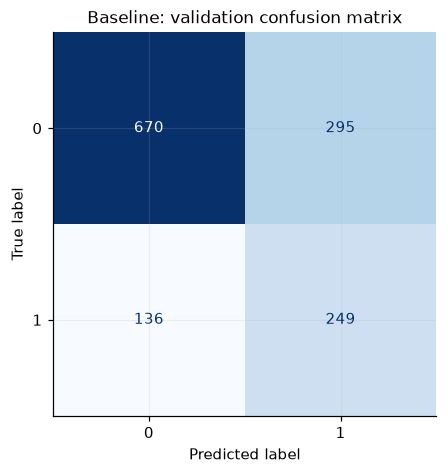

**5-fold stratified CV on the training part (preprocessing refitted inside each fold)**

,precision,recall,f1
fold 1,0.4807,0.6461,0.5512
fold 2,0.4642,0.6526,0.5425
fold 3,0.4774,0.6851,0.5627
fold 4,0.4930,0.6851,0.5734
fold 5,0.4799,0.6201,0.5411
mean,0.4790,0.6578,0.5542
std,0.0103,0.0277,0.0138


In [24]:
fig, ax = plt.subplots(figsize=(4.8, 4.2), layout='constrained')
ConfusionMatrixDisplay(confusion_matrix(y_va, val_pred), display_labels=['0', '1']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set(title='Baseline: validation confusion matrix')
plt.show()

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=cp.RANDOM_STATE)
cv_res = cross_validate(make_model(LogisticRegression(class_weight='balanced', max_iter=2000,
                                                      random_state=cp.RANDOM_STATE)),
                        X_tr, y_tr, cv=cv, scoring=['precision', 'recall', 'f1'])
cv_table = pd.DataFrame({m: cv_res[f'test_{m}'] for m in ['precision', 'recall', 'f1']})
cv_table.index = [f'fold {i + 1}' for i in range(len(cv_table))]
cv_table.loc['mean'] = cv_table.mean()
cv_table.loc['std'] = cv_table.iloc[:5].std()
show(cv_table, '5-fold stratified CV on the training part (preprocessing refitted inside each fold)')

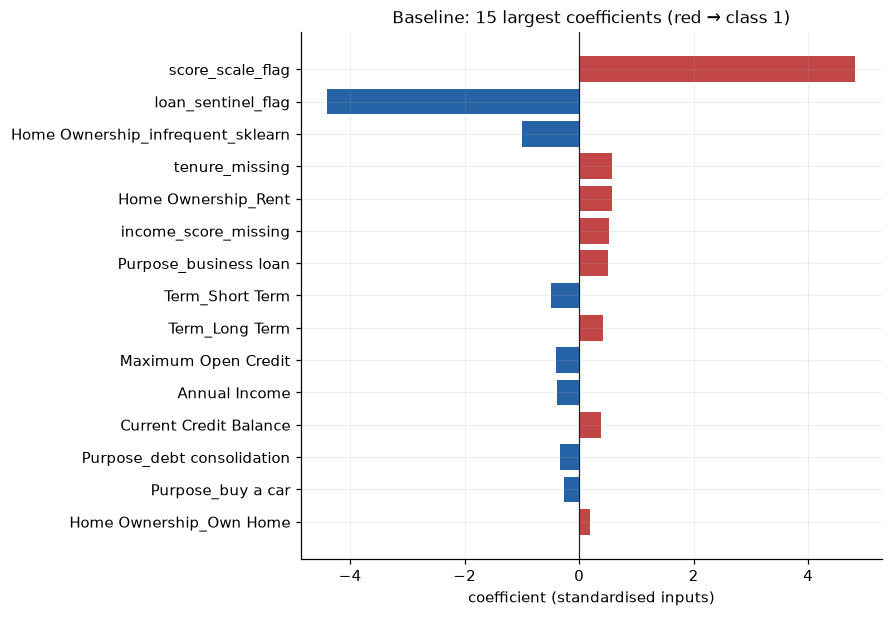

**Interpretation.** The baseline reaches Precision 0.458, Recall 0.647 and F1 0.536 for class 1 on the validation part; the dummy model has F1 = 0 because it never predicts class 1. The 5-fold CV F1 (0.554 ± 0.014) is close to the validation score, which is a consistency check, not a confidence interval or proof of generalisation. `class_weight="balanced"` trades precision for recall. The largest coefficients belong to the anomaly flags, which motivates the sensitivity check below.

In [25]:
coefs = pd.Series(baseline.named_steps['model'].coef_[0],
                  index=baseline.named_steps['preprocess'].named_steps['columns'].get_feature_names_out())
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(15)
fig, ax = plt.subplots(figsize=(8, 5.5), layout='constrained')
ax.barh(top.index[::-1], top.values[::-1], color=['#c24646' if v > 0 else '#2563a6' for v in top.values[::-1]])
ax.axvline(0, color='#222', linewidth=0.8)
ax.set(title='Baseline: 15 largest coefficients (red → class 1)', xlabel='coefficient (standardised inputs)')
plt.show()
r = results.loc['Logistic regression (baseline)']
note(f'The baseline reaches Precision {r.Precision:.3f}, Recall {r.Recall:.3f} and F1 {r.F1:.3f} for class 1 '
     f'on the validation part; the dummy model has F1 = 0 because it never predicts class 1. '
     f'The 5-fold CV F1 ({cv_table.loc["mean", "f1"]:.3f} ± {cv_table.loc["std", "f1"]:.3f}) is close to the validation '
     'score, which is a consistency check, not a confidence interval or proof of generalisation. `class_weight="balanced"` trades precision for recall. '
     'The largest coefficients belong to the anomaly flags, which motivates the sensitivity check below.')

### 6. Sensitivity check: anomaly flags
Same model and split, but `score_scale_flag` and `loan_sentinel_flag` are removed (the corrected
score and the imputed loan amount remain). This shows how dependent the baseline is on the two
patterns that the EDA marked as possible artefacts or leakage.

In [26]:
no_flags = make_model(LogisticRegression(class_weight='balanced', max_iter=2000, random_state=cp.RANDOM_STATE),
                      use_anomaly_flags=False)
no_flags.fit(X_tr, y_tr)
sensitivity = pd.DataFrame({
    'with anomaly flags (baseline)': scores(y_va, val_pred),
    'without anomaly flags': scores(y_va, no_flags.predict(X_va)),
}).T
show(sensitivity, 'Validation part: effect of the anomaly flags')
drop = sensitivity.iloc[0]['F1'] - sensitivity.iloc[1]['F1']
note(f'Removing the two flags changes validation F1 by {-drop:+.3f}. A large share of the signal comes from '
     'these patterns. If the team confirms they are recorded *before* the credit decision, they are legitimate '
     'features; otherwise neither result establishes deployment validity: corrected values, missingness and other correlated features may still reveal the artefact. Removing flags alone does not remove all possible leakage. Participant 3 should report both.')

**Validation part: effect of the anomaly flags**

,Precision,Recall,F1,Accuracy
with anomaly flags (baseline),0.4577,0.6468,0.5361,0.6807
without anomaly flags,0.3898,0.5974,0.4718,0.6185


**Interpretation.** Removing the two flags changes validation F1 by -0.064. A large share of the signal comes from these patterns. If the team confirms they are recorded *before* the credit decision, they are legitimate features; otherwise neither result establishes deployment validity: corrected values, missingness and other correlated features may still reveal the artefact. Removing flags alone does not remove all possible leakage. Participant 3 should report both.

### 7. Why these values? Training-only parameter search
The fixed reference above is retained so participant 3 can reproduce the earlier result. We now
compare **120 configurations × 5 identical stratified folds** on the 5,400 training rows only:

* `C = [0.01, 0.1, 1, 10, 100]`: lower C means stronger regularisation. C = 10 is one of the candidates; nothing assumes it is optimal.
* `class_weight = [None, 'balanced']`: evaluate whether weighting helps class-1 F1.
* rare-category `min_frequency = [1, 10, 20, 50]`: compare no practical grouping and three count cutoffs, learned inside each fold.
* `score_policy = ['divide', 'missing', 'raw']`: compare the hypothesised /10 repair, treating high scores as unknown, and keeping them unchanged.

The **division by ten** is a data repair hypothesis rather than a tuned parameter. The observed high
scores are all multiples of ten; /10 maps 6060–7510 to 606–751. This supports the scale-error hypothesis; what the source system meant is still unknown. `10+ years -> 10` is a lower bound for a censored tenure category.

Select the highest mean CV F1, refit that entire pipeline on 5,400 rows, then report validation
Precision, Recall, F1 and confusion matrices. No validation or test result changes the selection.
After the search the winning CV score is optimistic, and the 120 configurations cover only the grid above. The anomaly flags stay as experimental features: good validation metrics cannot show that they would be available before the outcome is known.


In [27]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'model__C': [0.01, 0.1, 1.0, 10.0, 100.0],
    'model__class_weight': [None, 'balanced'],
    'preprocess__columns__categorical__onehotencoder__min_frequency': [1, 10, 20, 50],
    'preprocess__clean__score_policy': ['divide', 'missing', 'raw'],
}
search = GridSearchCV(
    make_model(LogisticRegression(max_iter=2000, random_state=cp.RANDOM_STATE)),
    param_grid, scoring={'precision': 'precision', 'recall': 'recall', 'f1': 'f1'},
    refit='f1', cv=cv, n_jobs=2, error_score='raise', return_train_score=False,
)
search.fit(X_tr, y_tr)
tuned = search.best_estimator_
cv_search = pd.DataFrame(search.cv_results_)
cv_search.to_csv(OUT / 'parameter_search_cv.csv', index=False)
cols = ['rank_test_f1', 'param_model__C', 'param_model__class_weight',
        'param_preprocess__columns__categorical__onehotencoder__min_frequency',
        'param_preprocess__clean__score_policy', 'mean_test_precision',
        'mean_test_recall', 'mean_test_f1', 'std_test_f1']
show(cv_search.sort_values('rank_test_f1')[cols].head(10), 'Top training-CV configurations')
print('Chosen parameters (training CV only):', search.best_params_)
assert len(cv_search) == 120
note('All medians, scaling and category grouping are refitted inside each CV fold. '
     'Neither validation targets nor test targets enter the search.')


**Top training-CV configurations**

,rank_test_f1,param_model__C,param_model__class_weight,param_preprocess__columns__categorical__onehotencoder__min_frequency,param_preprocess__clean__score_policy,mean_test_precision,mean_test_recall,mean_test_f1,std_test_f1
43,1,0.1000,balanced,50,missing,0.4834,0.6623,0.5588,0.0127
39,2,0.1000,balanced,50,divide,0.4830,0.6623,0.5585,0.0140
47,3,0.1000,balanced,50,raw,0.4901,0.6461,0.5572,0.0148
40,4,0.1000,balanced,1,missing,0.4822,0.6597,0.5570,0.0131
71,5,1.0000,balanced,50,raw,0.4839,0.6565,0.5569,0.0158
42,6,0.1000,balanced,20,missing,0.4822,0.6591,0.5568,0.0137
67,7,1.0000,balanced,50,missing,0.4811,0.6604,0.5565,0.0137
111,8,100.0000,balanced,50,divide,0.4804,0.6610,0.5563,0.0136
41,9,0.1000,balanced,10,missing,0.4817,0.6584,0.5562,0.0131
46,10,0.1000,balanced,20,raw,0.4898,0.6435,0.5561,0.0135


Chosen parameters (training CV only): {'model__C': 0.1, 'model__class_weight': 'balanced', 'preprocess__clean__score_policy': 'missing', 'preprocess__columns__categorical__onehotencoder__min_frequency': 50}


**Interpretation.** All medians, scaling and category grouping are refitted inside each CV fold. Neither validation targets nor test targets enter the search.

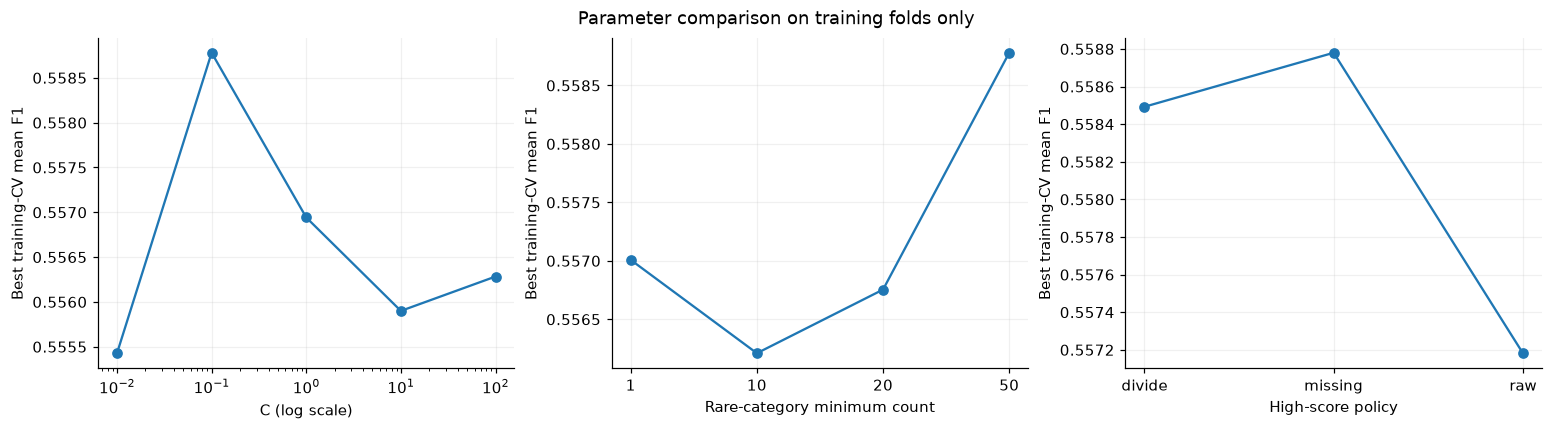

In [28]:
# Profile each candidate by its best mean CV F1 across the other settings.
# These curves describe the search, not independent generalisation estimates.
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), layout='constrained')
for ax, parameter, label in zip(axes,
        ['param_model__C',
         'param_preprocess__columns__categorical__onehotencoder__min_frequency',
         'param_preprocess__clean__score_policy'],
        ['C (log scale)', 'Rare-category minimum count', 'High-score policy']):
    profile = cv_search.groupby(parameter, dropna=False)['mean_test_f1'].max()
    if parameter == 'param_model__C':
        ax.semilogx(profile.index.astype(float), profile.values, marker='o')
    else:
        ax.plot(profile.index.astype(str), profile.values, marker='o')
    ax.set(xlabel=label, ylabel='Best training-CV mean F1')
fig.suptitle('Parameter comparison on training folds only')
plt.show()


**Validation reporting after settings are frozen**

,Precision,Recall,F1,Accuracy
Tuned logistic regression (CV-selected),0.4550,0.6442,0.5333,0.6785
Tuned settings without anomaly flags,0.3815,0.5896,0.4633,0.6104


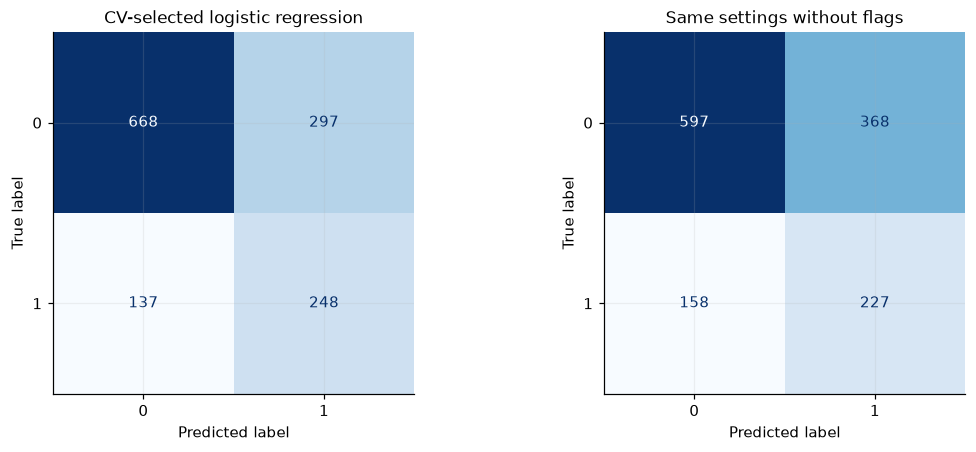

              precision    recall  f1-score   support

           0      0.830     0.692     0.755       965
           1      0.455     0.644     0.533       385

    accuracy                          0.679      1350
   macro avg      0.642     0.668     0.644      1350
weighted avg      0.723     0.679     0.692      1350



**Interpretation.** Training CV selects {'model__C': 0.1, 'model__class_weight': 'balanced', 'preprocess__clean__score_policy': 'missing', 'preprocess__columns__categorical__onehotencoder__min_frequency': 50}. Validation F1 is 0.533 with flags and 0.463 without flags. The no-flags model is an ablation at fixed settings, not a separately optimised model. Class labels remain literal 0/1 because their business meaning is undocumented. The CV-selected model does not improve on the fixed reference on validation; we report this rather than choosing new parameters after seeing validation results.

In [29]:
# Freeze settings before validation reporting. Same settings, remove only flags.
# ColumnTransformer columns are construction-time selections: rebuild via the public factory.
best = search.best_params_
tuned_no_flags = make_model(
    LogisticRegression(C=best['model__C'], class_weight=best['model__class_weight'],
                       max_iter=2000, random_state=cp.RANDOM_STATE),
    use_anomaly_flags=False,
    min_frequency=best['preprocess__columns__categorical__onehotencoder__min_frequency'],
    score_policy=best['preprocess__clean__score_policy'],
)
tuned_no_flags.fit(X_tr, y_tr)
tuned_pred = tuned.predict(X_va)
tuned_without_pred = tuned_no_flags.predict(X_va)
tuned_results = pd.DataFrame({
    'Tuned logistic regression (CV-selected)': scores(y_va, tuned_pred),
    'Tuned settings without anomaly flags': scores(y_va, tuned_without_pred),
}).T
show(tuned_results, 'Validation reporting after settings are frozen')
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')
for ax, pred, title in zip(axes, [tuned_pred, tuned_without_pred],
                           ['CV-selected logistic regression', 'Same settings without flags']):
    ConfusionMatrixDisplay.from_predictions(y_va, pred, labels=[0, 1],
        display_labels=['0', '1'], ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(title)
plt.show()
print(classification_report(y_va, tuned_pred, labels=[0, 1], digits=3, zero_division=0))
note(f'Training CV selects {search.best_params_}. Validation F1 is '
     f'{tuned_results.iloc[0].F1:.3f} with flags and {tuned_results.iloc[1].F1:.3f} without flags. '
     'The no-flags model is an ablation at fixed settings, not a separately optimised model. '
     'Class labels remain literal 0/1 because their business meaning is undocumented. '
     'The CV-selected model does not improve on the fixed reference on validation; '
     'we report this rather than choosing new parameters after seeing validation results.')


### 8. Outputs for part 3
Saved to `artifacts/participant2/`:

* `split_indices.csv`: row index and part (`train` / `valid`); load with `cp.load_split()`.
* `baseline_validation_metrics.csv`: baseline, dummy and no-flags metrics on the validation part.
* `baseline_validation_predictions.csv`: validation row, true label, baseline probability and prediction, used for error analysis.
* `baseline_summary.json`: configuration, metrics and the winning search parameters.
* `parameter_search_cv.csv`: all 120 configurations, every fold.
* `tuned_validation_predictions.csv`: tuned model predictions, both flag variants.

The same setup in code:

```python
import credit_pipeline as cp
X_full, y_full, X_test = cp.load_data()
idx_tr, idx_va = cp.load_split()
pre = cp.build_preprocessor(scale=False)   # tree models; scale=True for linear/distance models
```

Rules for part 3: compare all models on the same validation rows with Precision, Recall and F1 for class 1; choose hyperparameters and thresholds with training-only cross-validation; call `cp.load_test_labels()` once, for the final evaluation of the chosen model.

In [30]:
metrics_out = pd.concat([results, sensitivity.iloc[[1]], tuned_results])
metrics_out.index.name = 'model'
metrics_out.to_csv(OUT / 'baseline_validation_metrics.csv')
pd.DataFrame({'row': idx_va, 'y_true': y_va.to_numpy(), 'proba_class_1': val_proba,
              'y_pred': val_pred}).to_csv(OUT / 'baseline_validation_predictions.csv', index=False)
pd.DataFrame({'row': idx_va, 'y_true': y_va.to_numpy(),
              'proba_class_1': tuned.predict_proba(X_va)[:, 1], 'y_pred': tuned_pred,
              'proba_no_flags': tuned_no_flags.predict_proba(X_va)[:, 1],
              'y_pred_no_flags': tuned_without_pred}).to_csv(
                  OUT / 'tuned_validation_predictions.csv', index=False)
# Transform only: participant 3 owns final model selection and test evaluation.
tuned_test = tuned.named_steps['preprocess'].transform(X_test)
assert tuned_test.shape[0] == 750 and np.isfinite(tuned_test).all()
summary = {
    'parameter_search': {'best_params': search.best_params_, 'best_training_cv_f1': float(search.best_score_),
                         'candidates': len(cv_search), 'folds': 5, 'selection_metric': 'class-1 F1',
                         'threshold': 0.5, 'test_labels_used': False},
    'split': {'method': 'stratified train_test_split', 'valid_size': cp.VALID_SIZE,
              'random_state': cp.RANDOM_STATE, 'train_rows': len(idx_tr), 'valid_rows': len(idx_va)},
    'baseline': {'model': 'LogisticRegression', 'class_weight': 'balanced', 'max_iter': 2000, 'threshold': 0.5},
    'features_after_preprocessing': list(map(str, feature_names)),
    'validation_metrics': {k: {m: round(float(v), 4) for m, v in row.items()} for k, row in metrics_out.iterrows()},
    'cv_training_part': {m: {'mean': round(float(cv_table.loc['mean', m]), 4), 'std': round(float(cv_table.loc['std', m]), 4)}
                         for m in cv_table.columns},
}
(OUT / 'baseline_summary.json').write_text(json.dumps(summary, indent=2))
show(pd.DataFrame({'file': sorted(p.name for p in OUT.iterdir())}), 'Saved artefacts')

**Saved artefacts**

,file
0,baseline_summary.json
1,baseline_validation_metrics.csv
2,baseline_validation_predictions.csv
3,parameter_search_cv.csv
4,split_indices.csv
5,tuned_validation_predictions.csv


In [31]:
# Integrity checks
X_full_again, y_full_again, X_test_again = cp.load_data()
pd.testing.assert_frame_equal(X_full, X_full_again)
pd.testing.assert_frame_equal(X_test, X_test_again)
assert len(X_test) == 750 and X_test.index.equals(pd.RangeIndex(750))
assert Z_test.shape[0] == 750
assert cp.TARGET not in X_test.columns
display(Markdown('**ALL CHECKS PASSED** — source data unchanged, 750 test rows preserved in order, '
                 'test labels never loaded, all preprocessing fitted on the training part only.'))

**ALL CHECKS PASSED** — source data unchanged, 750 test rows preserved in order, test labels never loaded, all preprocessing fitted on the training part only.

<a id="part-3"></a>

# Part 3. Additional models, comparison and error analysis — Nikita Vassilenko

Project 5, Loan Approval, target `Credit Default`. Part 1 (Denis Shin's EDA) audited the data and found two anomalous values: Credit Score > 850 and Current Loan Amount = 99999999. Part 2 (Abylay Latiyev) put the preprocessing into `credit_pipeline.py`, fixed a 5,400 / 1,350 split and trained a logistic regression. Its validation result for class 1: Precision 0.458, Recall 0.647, F1 0.536. Without the anomaly flags F1 drops to 0.472.

This part trains two tree ensembles, tunes the decision threshold, compares everything with the logistic regression, analyses the errors and evaluates the chosen model on test once.

**Models.**

- *Random Forest* averages hundreds of trees, each grown on a bootstrap sample with a random subset of features at every split. Averaging reduces the variance of a single tree. `class_weight="balanced_subsample"` recomputes class weights inside every bootstrap sample, since class 1 is only 28.5 % of the data.
- *HistGradientBoosting* builds trees one after another, each fitting the errors of the sum of the previous ones (gradient descent on the log-loss). Features are binned into 255 intervals, which makes training fast, and missing values are handled natively. It is scikit-learn's implementation of the LightGBM approach, so no new dependency is needed.
- *Logistic regression* from part 2 stays as the reference point.

**Threshold.** By default class 1 is predicted when the probability is ≥ 0.5. With imbalanced classes that is rarely the best cut-off for F1. `TunedThresholdClassifierCV` tries 100 thresholds on 5 folds of the training part and keeps the one with the highest mean F1. Validation and test are not used. Studies on credit scoring report that threshold tuning often helps more than resampling such as SMOTE ([arXiv 1907.12996](https://export.arxiv.org/pdf/1907.12996)), and that tree ensembles usually, but not always, beat logistic regression ([MDPI Systems 13/7/581](https://www.mdpi.com/2079-8954/13/7/581), [SciTePress 2025](https://www.scitepress.org/publishedPapers/2025/137012/pdf/index.html)). Docs: [TunedThresholdClassifierCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TunedThresholdClassifierCV.html).

**Rules.** The split comes only from `cp.load_split()`. All parameters and thresholds are fitted on the training part. Validation is used only to compare and choose models. Test labels are loaded once, in section 6.

In [32]:
import json
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_validate

import credit_pipeline as cp
import participant3 as p3

warnings.filterwarnings('ignore', category=UserWarning)
OUT = Path('artifacts/participant3')
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)

X_full, y_full, X_test = cp.load_data()
idx_tr, idx_va = cp.load_split()
X_tr, y_tr = X_full.loc[idx_tr], y_full.loc[idx_tr]
X_va, y_va = X_full.loc[idx_va], y_full.loc[idx_va]
print(f'train {len(X_tr)}, validation {len(X_va)}, test {len(X_test)}; class 1 share in train {y_tr.mean():.3f}')

train 5400, validation 1350, test 750; class 1 share in train 0.285


### 1. Cross-validation on the training part

Each model runs in two variants: with the anomaly flags (`score_scale_flag`, `loan_sentinel_flag`) and without them. First a 5-fold CV at threshold 0.5, then threshold tuning on the same folds. ROC AUC does not depend on the threshold and shows how well the model ranks applicants.

In [33]:
cv = StratifiedKFold(5, shuffle=True, random_state=cp.RANDOM_STATE)
rows, tuned = [], {}
for flags in (True, False):
    for name, pipe in p3.make_models(flags).items():
        res = cross_validate(pipe, X_tr, y_tr, cv=cv, scoring=['precision', 'recall', 'f1', 'roc_auc'])
        t = p3.tune_threshold(pipe, X_tr, y_tr)
        tuned[(name, flags)] = t
        rows.append({'model': name, 'flags': flags,
                     **{m: res[f'test_{m}'].mean() for m in ['precision', 'recall', 'f1', 'roc_auc']},
                     'f1_sd': res['test_f1'].std(),
                     'tuned_threshold': t.best_threshold_, 'tuned_cv_f1': t.best_score_})
cv_table = pd.DataFrame(rows)
cv_table.to_csv(OUT / 'cv_comparison.csv', index=False)
cv_table.round(3)

,model,flags,precision,recall,f1,roc_auc,f1_sd,tuned_threshold,tuned_cv_f1
0,logreg,True,0.4790,0.6580,0.5540,0.7780,0.0120,0.5050,0.5560
1,random_forest,True,0.5790,0.4920,0.5320,0.7740,0.0180,0.4210,0.5530
2,hist_gb,True,0.5180,0.5140,0.5160,0.7570,0.0160,0.3540,0.5380
3,logreg,False,0.4060,0.6050,0.4860,0.6760,0.0110,0.4340,0.4940
4,random_forest,False,0.4770,0.4120,0.4420,0.7040,0.0190,0.3590,0.5120
5,hist_gb,False,0.4280,0.4840,0.4540,0.6880,0.0120,0.2870,0.5080


Columns `precision` to `f1_sd` use threshold 0.5. `tuned_cv_f1` uses the tuned threshold on the same five folds; the threshold was picked on these folds, so this number is slightly optimistic. The fair comparison is validation in the next section.

At threshold 0.5 the logistic regression has the best CV F1 (0.554) and ROC AUC (0.778). The forests are more precise but miss more defaults; after tuning, Random Forest catches up (0.553). Removing the flags costs 0.06–0.09 F1 at threshold 0.5 (Random Forest loses the most, 0.532 → 0.442).

### 2. Validation comparison

Each model with its tuned threshold was fitted on the 5,400 training rows and now predicts the 1,350 validation rows once. The part 2 rows are copied from its metrics file.

In [34]:
val_rows, proba = [], {}
for (name, flags), t in tuned.items():
    p = t.predict_proba(X_va)[:, 1]
    proba[(name, flags)] = p
    val_rows.append({'model': name, 'flags': flags, 'threshold': t.best_threshold_,
                     **p3.class1_metrics(y_va, (p >= t.best_threshold_).astype(int)),
                     'roc_auc': roc_auc_score(y_va, p)})
p2 = pd.read_csv('artifacts/participant2/baseline_validation_metrics.csv')
p2 = p2.set_index('model').loc[['Logistic regression (baseline)', 'without anomaly flags']]
for (_, r), flags in zip(p2.iterrows(), (True, False)):
    val_rows.append({'model': 'logreg (part 2, threshold 0.5)', 'flags': flags, 'threshold': 0.5,
                     'precision': r.Precision, 'recall': r.Recall, 'f1': r.F1, 'roc_auc': np.nan})
val_table = pd.DataFrame(val_rows).sort_values(['flags', 'f1'], ascending=False)
val_table.to_csv(OUT / 'validation_comparison.csv', index=False)
val_table.round(3)

,model,flags,threshold,precision,recall,f1,roc_auc
6,"logreg (part 2, threshold 0.5)",True,0.5000,0.4580,0.6470,0.5360,NaN
0,logreg,True,0.5050,0.4610,0.6390,0.5350,0.7470
1,random_forest,True,0.4210,0.4520,0.6160,0.5210,0.7320
2,hist_gb,True,0.3540,0.4120,0.6910,0.5170,0.7320
5,hist_gb,False,0.2870,0.3580,0.8260,0.4990,0.6640
4,random_forest,False,0.3590,0.3650,0.7480,0.4910,0.6710
3,logreg,False,0.4340,0.3550,0.7350,0.4780,0.6490
7,"logreg (part 2, threshold 0.5)",False,0.5000,0.3900,0.5970,0.4720,NaN


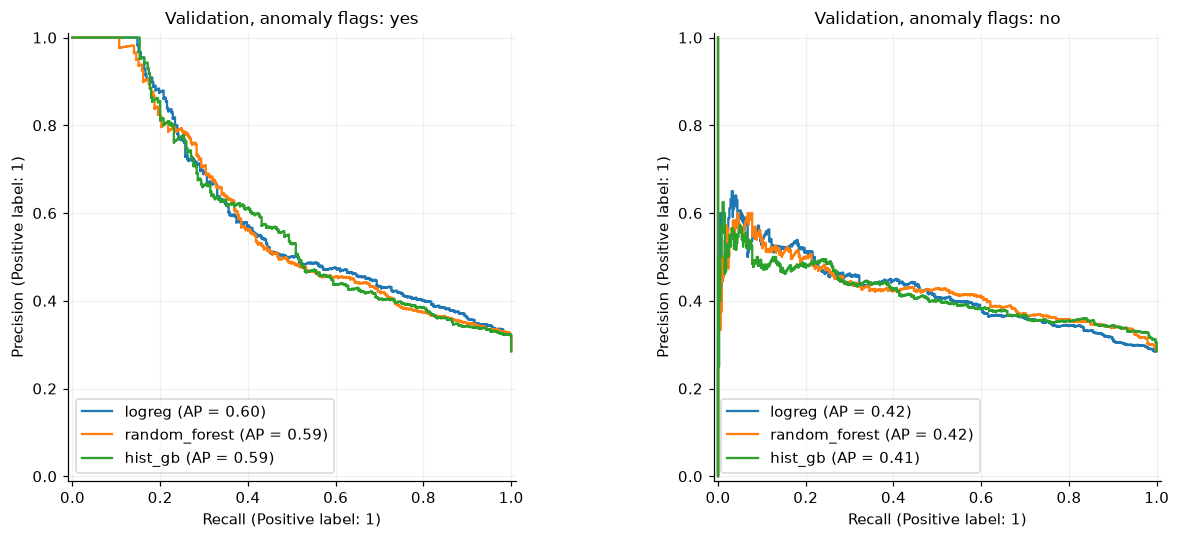

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, flags in zip(axes, (True, False)):
    for name in ['logreg', 'random_forest', 'hist_gb']:
        PrecisionRecallDisplay.from_predictions(y_va, proba[(name, flags)], name=name, ax=ax)
    ax.set_title(f'Validation, anomaly flags: {"yes" if flags else "no"}')
fig.tight_layout(); fig.savefig(FIG / 'pr_curves.png', dpi=120); plt.show()

With the flags, neither tree model beats the baseline: Random Forest reaches F1 0.521 and HistGradientBoosting 0.517, against 0.535–0.536 for logistic regression. Without the flags the order flips: HistGradientBoosting 0.499 and Random Forest 0.491 are ahead of logistic regression (0.478 tuned, 0.472 in part 2). Their tuned thresholds are low (0.29–0.36), so they buy recall (0.75–0.83) with precision.

### 3. Feature contribution

`permutation_importance` shuffles one raw validation column and measures the drop in F1, without refitting. The anomaly flags are derived from `Credit Score` and `Current Loan Amount`, so their effect shows up in the importance of those two columns.

In [36]:
best_tree = val_table[val_table.model.isin(['random_forest', 'hist_gb']) & val_table['flags']].iloc[0].model
imp_rows = []
for flags in (True, False):
    r = permutation_importance(tuned[(best_tree, flags)], X_va, y_va, scoring='f1',
                               n_repeats=10, random_state=cp.RANDOM_STATE, n_jobs=-1)
    imp_rows.append(pd.Series(r.importances_mean, index=X_va.columns, name=f'flags={flags}'))
importance = pd.concat(imp_rows, axis=1).sort_values('flags=True', ascending=False)
importance.to_csv(OUT / 'permutation_importance.csv')
print('model:', best_tree)
importance.round(3).head(10)

model: random_forest


,flags=True,flags=False
Credit Score,0.0730,0.0050
Current Loan Amount,0.0400,0.0410
Annual Income,0.0370,0.0230
Term,0.0310,0.0110
Maximum Open Credit,0.0150,0.0010
Home Ownership,0.0120,-0.0030
Years in current job,0.0100,0.0060
Purpose,0.0100,-0.0010
Months since last delinquent,0.0090,-0.0010
Monthly Debt,0.0040,0.0070


With the flags, `Credit Score` is the most important column (F1 drop 0.073). Without them its importance falls to 0.005: almost all of its value comes from the "score above 850" marker. `Current Loan Amount` keeps the same importance (0.040 vs 0.041), so the forest also learns the 99999999 value from the raw amount.

### 4. Model choice

The rule is fixed before test is touched: take the highest validation F1 among the tuned models. If a simpler model is within 0.01, take the simpler one (logreg, then random_forest, then hist_gb). On a tie the variant with flags wins, because parts 1 and 2 kept them as domain cleaning.

In [37]:
order = {'logreg': 0, 'random_forest': 1, 'hist_gb': 2}
cand = val_table[val_table.model.isin(order)].copy()
best_f1 = cand.f1.max()
close = cand[cand.f1 >= best_f1 - 0.01].assign(rank=lambda d: d.model.map(order) - d['flags'].astype(int) * 0.1)
chosen = close.sort_values('rank').iloc[0]
CHOSEN = (chosen.model, bool(chosen['flags']))
print('chosen:', CHOSEN, f'validation F1 {chosen.f1:.3f}')

chosen: ('logreg', True) validation F1 0.535


### 5. Error analysis

Errors of the chosen model on validation. FN is a missed class 1, FP a false alarm. Error shares are computed per group and compared with the part 2 logistic regression on the same rows.


Term (share of rows by error type):
kind           FN     FP     ok
Term                           
Long Term  0.0190 0.4570 0.5240
Short Term 0.1330 0.1250 0.7420

score_missing (share of rows by error type):
kind              FN     FP     ok
score_missing                     
False         0.1030 0.1770 0.7200
True          0.1010 0.3500 0.5490

score_scale_flag (share of rows by error type):
kind                 FN     FP     ok
score_scale_flag                     
0                0.1080 0.2230 0.6690
1                0.0000 0.0000 1.0000

loan_sentinel_flag (share of rows by error type):
kind                   FN     FP     ok
loan_sentinel_flag                     
0                  0.1160 0.2400 0.6440
1                  0.0000 0.0000 1.0000

Home Ownership (share of rows by error type):
kind               FN     FP     ok
Home Ownership                     
Have Mortgage  0.0000 0.0000 1.0000
Home Mortgage  0.1210 0.1920 0.6870
Own Home       0.1320 0.1320 0.7370
Rent      

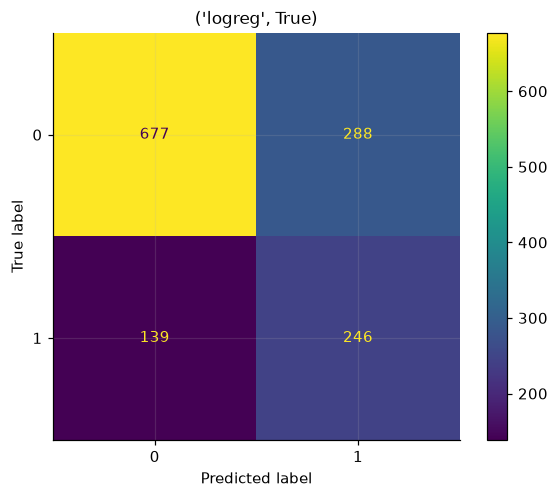

In [38]:
t = tuned[CHOSEN]
p = proba[CHOSEN]
pred = (p >= t.best_threshold_).astype(int)
clean = cp.DomainCleaner().fit(X_tr).transform(X_va)
err = pd.DataFrame({'row': X_va.index, 'y_true': y_va.values, 'proba': p, 'y_pred': pred,
                    'model': f'{CHOSEN[0]}, flags={CHOSEN[1]}'})
err.to_csv(OUT / 'validation_predictions.csv', index=False)
err['kind'] = np.select([(err.y_true == 1) & (err.y_pred == 0), (err.y_true == 0) & (err.y_pred == 1)],
                        ['FN', 'FP'], 'ok')
seg = pd.DataFrame({'Term': X_va.Term.values,
                    'score_missing': X_va['Credit Score'].isna().values,
                    'score_scale_flag': clean.score_scale_flag.values,
                    'loan_sentinel_flag': clean.loan_sentinel_flag.values,
                    'Home Ownership': X_va['Home Ownership'].values})
for col in seg:
    g = pd.concat([seg[col], err.kind], axis=1).groupby(col).kind.value_counts(normalize=True).unstack(fill_value=0)
    print(f'\n{col} (share of rows by error type):'); print(g.round(3))
ConfusionMatrixDisplay.from_predictions(y_va, pred); plt.title(f'{CHOSEN}'); plt.savefig(FIG / 'confusion_chosen.png', dpi=120); plt.show()

In [39]:
base = pd.read_csv('artifacts/participant2/baseline_validation_predictions.csv').set_index('row').loc[err.row]
b_ok = base.y_pred.values == base.y_true.values
c_ok = err.y_pred.values == err.y_true.values
print('fixed vs baseline:', int((~b_ok & c_ok).sum()))
print('broken vs baseline:', int((b_ok & ~c_ok).sum()))
print('wrong in both:', int((~b_ok & ~c_ok).sum()))
print('\nmissed class 1 (FN) vs found class 1 (TP), feature medians:')
fn = err.kind.values == 'FN'; tp = (err.y_true.values == 1) & (err.y_pred.values == 1)
num = ['Credit Score', 'Annual Income', 'Current Loan Amount', 'Monthly Debt', 'Years of Credit History']
pd.DataFrame({'FN': clean.loc[fn, num].median(), 'TP': clean.loc[tp, num].median()}).round(1)

fixed vs baseline: 7
broken vs baseline: 3
wrong in both: 424

missed class 1 (FN) vs found class 1 (TP), feature medians:


,FN,TP
Credit Score,732.5000,710.0000
Annual Income,"1,056,077.0000","988,009.5000"
Current Loan Amount,"220,066.0000","330,033.0000"
Monthly Debt,"15,840.0000","16,500.5000"
Years of Credit History,17.1000,16.8000


What the errors show:

- Rows with either flag are always classified correctly. All remaining errors come from ordinary rows.
- Long-term loans are the main source of false alarms: 45.7 % of them are FP, against 12.5 % for short-term loans. The model treats `Term = Long Term` as a strong risk sign and flags almost every such applicant.
- Rows with a missing Credit Score (and income) get FP twice as often as the rest (35.0 % vs 17.7 %): median imputation alone does not recover what is lost.
- Missed defaults look like good applicants: higher median score (732.5 vs 710) and income, smaller loans. Nothing in the 16 features separates them.
- The tuned model differs from the part 2 baseline on only 10 of 1,350 rows (7 fixed, 3 broken). 424 rows are wrong for both; changing model settings does not reach them, the features would have to change.

### 6. Final test evaluation

The chosen model is refitted on all 6,750 train rows (training part + validation), and its threshold is tuned again on 5 folds of those rows. Then test labels are loaded once. All 750 test rows stay in place.

In [40]:
pipe = p3.make_models(CHOSEN[1])[CHOSEN[0]]
final = p3.tune_threshold(pipe, X_full, y_full)
test_pred = final.predict(X_test)
assert len(test_pred) == len(X_test) == 750
y_test = cp.load_test_labels()  # the only call
test_metrics = {'model': CHOSEN[0], 'anomaly_flags': CHOSEN[1], 'threshold': float(final.best_threshold_),
                **p3.class1_metrics(y_test, test_pred),
                'roc_auc': float(roc_auc_score(y_test, final.predict_proba(X_test)[:, 1]))}
(OUT / 'test_metrics.json').write_text(json.dumps(test_metrics, indent=2))
test_metrics

{'model': 'logreg',
 'anomaly_flags': True,
 'threshold': 0.505158127128665,
 'precision': 0.39932885906040266,
 'recall': 0.6329787234042553,
 'f1': 0.4897119341563786,
 'roc_auc': 0.7559438176724464}

### 7. Conclusion

| Model (class 1) | Precision | Recall | F1 |
|---|---|---|---|
| Logistic regression, part 2, validation | 0.458 | 0.647 | 0.536 |
| Logistic regression, tuned threshold, validation | 0.461 | 0.639 | 0.535 |
| Random Forest, tuned threshold, validation | 0.452 | 0.616 | 0.521 |
| HistGradientBoosting, tuned threshold, validation | 0.412 | 0.691 | 0.517 |
| **Logistic regression, final, test** | **0.399** | **0.633** | **0.490** |

1. The tree ensembles did not beat logistic regression on this data. With the anomaly flags it stays first in CV and on validation, so it is the final model. The trees win only without the flags (F1 0.499 vs 0.478), when the remaining signal is non-linear and weak.
2. Threshold tuning on training folds moved the logistic regression threshold only to 0.505; for this model `class_weight="balanced"` already does the job. For the trees it mattered: with thresholds of 0.29–0.42 their validation recall is 0.62–0.83, against 0.41–0.51 in CV at threshold 0.5.
3. On test F1 is 0.490, lower than 0.535 on validation, while ROC AUC stays close (0.756 vs 0.747). Ranking quality held; precision dropped. Validation was not fully blind, because the EDA looked at the whole training target and the preprocessing rules came from it. Test is the honest estimate.
4. The two anomaly flags give most of the gain: removing them costs 0.06–0.09 F1 in CV and 0.02–0.06 on validation, and every flagged row is predicted correctly. The data does not tell whether this is a real signal (a scoring system that writes risky clients on a different scale) or an artefact of how the dataset was assembled. If the second is true, the realistic quality is the no-flags row, about F1 0.47–0.50.
5. Most errors are false alarms on long-term loans and on applicants with no credit score. More data on these groups would help more than another model.

Artifacts: `artifacts/participant3/` (`cv_comparison.csv`, `validation_comparison.csv`, `permutation_importance.csv`, `validation_predictions.csv`, `test_metrics.json`, `figures/`).